# Project 03: Monte Carlo Study on Effects of Reflector Material and Size on the Neutron Multiplication Factor $k$ in a U-235 Fission Reactor System
**Name:** Jose Felicio

> **Portfolio edition:** cleaned-up version of a PHYS 210 course project. This is an educational model, not a validated engineering code. Figure results are generated by executing the notebook from top to bottom; the saved outputs from the original submission have been cleared following code corrections.


## Introduction

This project simulates a cube-shaped reactor that is divided into two regions, the "core" and the "reflector". The core, made up of uranium dioxide ($\mathrm{UO_2}$), is located at the centre of the reactor and is where the neutrons can undergo fission. The reflector is the region surrounding the core and is made up of a "moderator" which are materials that are capable of slowing down the neutrons during collision, a process called "neutron thermalization" [1], without causing it to undergo fission. Some commonly used moderators include light water $(\mathrm{H_2O})$, heavy water $(\mathrm{D_2O})$, and graphite $(\mathrm{C\text{-}12})$ [2] which are the materials used for this simulation.

In our model, the reflector allows neutrons to "scatter", causing it to lose energy, i.e., thermalization. However, there is also a chance of the neutrons being captured (absorbed) by the reflector material or leaving the reactor (leak), thereby making it impossible for these neutrons to return to the core and undergo fission.  

A high amount of neutron scattering in the reflector typically causes its energy to drop down to thermal levels and if they end up back in the fuel region after scattering, the probability of undergoing fission increases tremendously due to the thermal cross section of U-235 fission being much higher compared to fast U-235 fission [3].

If they end up back in the fuel region at the end of the scatter, then they are captured and either undergo fission or are absorbed. If they leave the reactor, we consider this to be a "leak" and they can no longer go back inside the reactor. For numerical practicality, we cap the number of collisions per transport segment (200 in both regions in the main runs). Reaching a cap is recorded as a **numerical cutoff**, not as physical absorption. This distinction matters for interpreting terminal outcomes.

We then study and compare how each of these materials that make up the reflector affect the multiplication factor $k$. We do not try to fine-tune the system to exactly $k = 1$. Instead, we compare how different reflector materials and thicknesses shift $k$ up or down relative to each other, within our simplified model.

**Research Question:** In a simplified two-region Monte Carlo model of a U-235 system, how do different reflector materials and thickness influence the multiplication factor $k$?

## Model

### Geometry

We model a **two-region cubic system** centred at the origin:

- **Core (fuel region):** cube of side length $a_{\text{core}}$. Fission is allowed *only inside this region*.
- **Reflector (moderator region):** a surrounding cubical shell of thickness $t$ on every face, giving an outer cube
  $$
  a_{\text{out}} = a_{\text{core}} + 2t.
  $$
- **Outer boundary condition:** the surface of the outer cube is a *vacuum (leakage) boundary*. Any neutron that crosses it is removed (lost by leakage).

In the code, $a_{\text{core}}$ and $t$ are control parameters. In the main runs, the core size is set as
$$
a_{\text{core}} = L_{\text{scale}}\times w_{\text{lattice}},
$$
where $w_{\text{lattice}}$ is the width/length of our fuel lattice as approximated by the typical dimensions of a BWR (boiling-water reactor) based on the MIT data for 9×9 BWR bundles [4]. It gives 14.27 mm for the fuel pin pitch and so the distance from the first pin to the last pin would be $1.427\times(9-1)\approx11.42\ \mathrm{cm}$. Adding one rod diamter to get from outer surface to outer surface gives $11.42+1.118\approx12.54\ \mathrm{cm}$. Allowing roughly about 1 cm for the channel box and other structural materials leads to an overall assembly width of $\approx13.5-14$ cm. $L_{\text{scale}}$ is justified as being the number of lattices there are in our reactor so, for example, an $L_{\text{scale}}=4$ and $w_{\text{lattice}}=12\ \text{cm}$ gives a total core side length of $a_{\text{core}}=48\ \text{cm}$ and reflector thickness is varied (e.g., $t\in{0,5,10,20,40}\ \text{cm}$) depending on the investigation.

---

### Materials and Homogenization

#### Fuel Composition

Fuel is $\mathrm{UO_2}$ with *5% enrichment* in U-235 by mass (with U-238 making up the remainder) [5]. Using uranium molar masses $M_{235}, M_{238}$, the *atomic fraction* used in number densities is
$$
f_{235}=\frac{(0.05/M_{235})}{(0.05/M_{235})+(0.95/M_{238})},\qquad f_{238}=1-f_{235}.
$$

From $\mathrm{UO_2}$ density $\rho_{\mathrm{UO_2}}$ and molar mass $M_{\mathrm{UO_2}}$, the molecule number density is
$$
N_{\mathrm{UO_2}}=\frac{\rho_{\mathrm{UO_2}}N_A}{M_{\mathrm{UO_2}}}\ \text{[6]}.
$$
Then
$$
N_{235}=f_{235}N_{\mathrm{UO_2}},\quad N_{238}=f_{238}N_{\mathrm{UO_2}},\quad N_{O}=2N_{\mathrm{UO_2}}.
$$

#### Core Moderator Mixing

To prevent $k$ from being too low due to fast neutrons born from fission, the core is treated as a *homogenized mixture* of fuel $\mathrm{UO_2}$ and a chosen core moderator (e.g. light water), using a fuel volume fraction $v_f$:

- fuel nuclide number densities scaled by $v_f$,
- moderator nuclide number densities scaled by $1-v_f$.

For any nuclide (i),
Then the homogenized (volume-averaged) number density used for transport in the core is
$$
N_i^{\text{core}} = v_f\,N_i^{(\mathrm{UO_2})} + (1-v_f)\,N_i^{(\mathrm{mod})}.
$$

This preserves the correct number of atoms per unit total core volume while treating the mixture as spatially uniform.

A reasonable estimate of $v_f$ for a BWR-assembly-like mixture can be obtained from the moderator-to-fuel atomic ratio H/HM ("hydrogen to heavy metal") as reported in the MIT 9x9 BWR bundle data (H/HM=4.53) [4]. Using pure-material number densities (scaled by volume fraction) with light water as the core moderator, the atomic ratio implied by a volume fraction $v_f$ of $\mathrm{UO_2}$ and $(1-v_f)$ of $\mathrm{H_2O}$ is
$$
\frac{\mathrm{H}}{\mathrm{HM}}\approx\frac{2N_{\mathrm{H_2O}}(1-v_f)}{N_{\mathrm{UO_2}}v_f},
$$
since each water molecule contributes 2 H atoms and each $\mathrm{UO_2}$ contributes 1 $U$ atom. Set this equal to the target ratio ($R=\mathrm{H/HM}=4.53$) and solve for $v_f$:
$$
R = \frac{2N_{\mathrm{H_2O}}(1-v_f)}{N_{\mathrm{UO_2}}v_f}
\quad\Rightarrow\quad
R v_f N_{\mathrm{UO_2}} = 2N_{\mathrm{H_2O}}(1-v_f).
$$

Expand the right-hand side and collect $v_f$ terms:
$$
R v_f N_{\mathrm{UO_2}} = 2N_{\mathrm{H_2O}} - 2v_f N_{\mathrm{H_2O}}
$$
$$
v_f\left(R N_{\mathrm{UO_2}} + 2N_{\mathrm{H_2O}}\right) = 2N_{\mathrm{H_2O}}.
$$

So the volume fraction is
$$
v_f=\frac{2N_{\mathrm{H_2O}}}{R N_{\mathrm{UO_2}} + 2N_{\mathrm{H_2O}}}.
$$

Using our calculated number densities (see Appendex 1.2), $N_{\mathrm{H_2O}}\approx3.34\cdot10^22\ \mathrm{cm^-3}, N_{\mathrm{UO_2}}\approx2.45\cdot10^{22}\ \mathrm{cm^{-3}}$, we find
$$
v_f=\frac{2\cdot3.34\cdot10^{22}}{(4.53\cdot2.45+2\cdot3.34)\cdot10^{22}}\approx0.38.
$$

Thus, a reasonable choice which we used in our simulation is `vf_uo2 = 0.40` as the representative fuel volume fraction in the core.

#### Reflector Material

The reflector is *one pure moderator* per run (graphite / light water / heavy water), with constant density and constant isotopic composition. The reflector contains *no fissile material* (no fission in the reflector).

---

### Neutron source: Watt fission spectrum

Each emitted (birth) neutron energy is sampled from a *Watt spectrum* [7] for U-235 fission:
$$
p(E)\,dE=c e^{-E/a}\sinh\left(\sqrt{bE}\right)\,dE\ \text{[8]},
$$
with parameters (as used in the code)
$$
a = 0.988\ \text{MeV} = 9.88\times10^5\ \text{eV},\qquad
b = 2.249\ \text{MeV}^{-1} = 2.249\times10^{-6}\ \text{eV}^{-1},
$$
and (c) a normalization constant.

Sampling is done using an acceptance–rejection method (implemented in the code via intermediate constants (K,L,M)) as demonstrated by Miao and Jin (2024) [9].

Initial directions are *isotropic*, sampled by choosing a uniform $\phi\in[0,2\pi)$ and a uniform cosine of polar angle $\mu=\cos{\theta}\in[-1,1]$, which ensures equal probability for equal solid angles.

Initial source positions are sampled uniformly in the core volume.

---

### Energy-dependent cross sections from ENDF/B-VIII (JANIS) [10]

For a region with nuclide number densities $N_i$, microscopic cross sections $\sigma_{x,i}(E)$, and reaction type $x$, the *macroscopic* cross section is
$$
\Sigma_x(E) = \sum_i N_i\,\sigma_{x,i}(E)\ \text{[11]}.
$$

We use the standard decomposition
$$
\Sigma_t(E)=\Sigma_s(E)+\Sigma_a(E),\qquad \Sigma_a(E)=\Sigma_f(E)+\Sigma_c(E),
$$
where (s) = scatter, (f) = fission, (c) = non-fission capture.

To avoid ad-hoc, piecewise cross-section models, we use microscopic cross sections tabulated from the ENDF/B-VIII nuclear data library and exported in CSV files through the JANIS databank. For each isotope and reaction channel used in the Monte Carlo, JANIS provides a table of energy $E$ and cross section $\sigma(E)$.

#### Data files and reaction channels

For each nuclide $i$, we load separate JANIS tables for:
- **elastic scattering** $\sigma_{s,i}(E)$,
- **radiative capture** $\sigma_{c,i}(E)$ (non-fission absorption),
- **fission** $\sigma_{f,i}(E)$ (only for fissile nuclides such as U-235 and U-238)

In this project the set includes U-235, U-238, O-16, C-12, H-2, and H-1 using ENDF/B-VIII data.

Units: JANIS exports $\sigma$ in barns and $E$ in eV. In the simulation, we ensure a consistent convention in eV and $\sigma$ converted to cm$^2$ before forming macroscopic cross sections.

#### Robust parsing of JANIS exports

JANIS CSV exports often contain header text before the numeric table. We scan the file line-by-line to find the first numeric data row, then read the two numeric columns (energy and cross section) using pandas. Non-numeric rows and missing values are dropped.

This yields arrays $E_k$ and $\sigma_k$ defining the tabulated microscopic cross section.

#### Log–log interpolation

As recommended by the ENDF-6 Formats Manual [12], we use a log-log interpolation procedure [13]: 

1. Filter out any non-positive or non-finite values.
2. Sort by energy.
3. Define
   $$
   \log E_k = \ln(E_k),\qquad \log \sigma_k = \ln(\sigma_k).
   $$
4. For an arbitrary energy $E$ within the tabulated range, compute
   $$
   \log\sigma(E) \approx \text{interp}\big(\log E;\{\log E_k\},\{\log\sigma_k\}\big),
   \qquad
   \sigma(E)=\exp(\log\sigma(E)).
   $$

This log–log interpolation behaves like a locally power-law fit between tabulated points and is numerically stable over wide energy ranges.

#### Handling energies outside the tabulated range

To avoid uncontrolled extrapolation, we track the valid energy range $[E_{\min},E_{\max}]$ of each table. When an energy lies outside a particular tabulated range, the code uses **mode = "clamp"**, evaluating at the nearest available endpoint instead of extrapolating. The `wrap_sigma` helper also supports **mode = "raise"** for strict range checking, but the transport runs use clamping. Endpoint clamping introduces a model approximation at the limits.

#### Use in transport: macroscopic cross sections and reaction sampling

At runtime, microscopic cross sections are queried at the neutron’s current energy and converted into macroscopic cross sections via
$$
\Sigma_x(E) = \sum_i N_i\,\sigma_{x,i}(E),
$$
where $N_i$ is the number density of nuclide $i$ in the current region and $x\in\{s,c,f\}$.

We then form
$$
\Sigma_a(E)=\Sigma_c(E)+\Sigma_f(E),\qquad \Sigma_t(E)=\Sigma_s(E)+\Sigma_a(E),
$$
which are used to sample:
- the distance to collision $s=-\ln\xi/\Sigma_t(E)$,
- the reaction type at collision with probabilities $\Sigma_s/\Sigma_t$, $\Sigma_c/\Sigma_t$, and $\Sigma_f/\Sigma_t$.

---

### Monte Carlo transport (one neutron history)

A neutron is tracked as straight-line flights separated by collisions. At any step it has position $\mathbf{r}$, direction $\hat{u}$, and energy $E$.

#### 1) Sample distance to next collision

In a homogeneous region the distance-to-collision is exponential:
$$
s = -\frac{\ln X}{\Sigma_t(E)},\qquad X\sim U(0,1).
$$

#### 2) Boundary crossing vs collision

Compute the distance $s_b$ to the next geometric boundary (core/reflector boundary or the outer boundary) along $\hat{u}$:

- If $s < s_b$: move to collision point $\mathbf{r}\leftarrow \mathbf{r}+s\hat{u}$ and collide.
- If $s_b \le s$: move to boundary $\mathbf{r}\leftarrow \mathbf{r}+s_b\hat{u}$:

  - if crossing **core -> reflector**, update the region/material and continue,
  - if crossing the **outer boundary**, leak and terminate the history.

#### 3) Choose collision reaction type

At a collision in the current region, choose the reaction using macroscopic probabilities:
$$
P(s)=\frac{\Sigma_s}{\Sigma_t},\qquad
P(f)=\frac{\Sigma_f}{\Sigma_t},\qquad
P(c)=\frac{\Sigma_c}{\Sigma_t}.
$$

- **Capture:** neutron terminates.
- **Fission:** neutron terminates and produces “children” (see next section).
- **Scatter:** neutron survives, energy and direction change.

---

### Elastic scattering (moderation model)

Moderation is modeled as **elastic scattering** on stationary target nuclei of mass ratio (A) (in neutron-mass units).

Define
$$
\alpha=\left(\frac{A-1}{A+1}\right)^2\ \text{[14]}.
$$

Assuming isotropic scattering in the center-of-mass frame, the post-collision energy is sampled as
$$
E' = E\big[\alpha + (1-\alpha)X\big],\qquad X\sim U(0,1),
$$
so $E'$ is uniform on $[\alpha E,E]$.

The outgoing direction is resampled isotropically (same $\mu,\phi$) sampling as above, and the direction vector is rotated accordingly.

---

### Fission reproduction and the definition of $k$

#### Mean children $\nu$ and integer sampling

Each fission event produces an integer number of neutrons $n$ sampled from the chosen mean $\nu$ using a floor/ceil scheme:
$$
n = \lfloor \nu \rfloor + B,\qquad B\sim \text{Bernoulli}(\nu-\lfloor\nu\rfloor)\ \text{[15]},
$$
so $E[n]=\nu$.

#### “Fission-to-fission” $k$ (matches the project definition)

This project defines $k$ to represent: "the average number of neutrons from each fission event that cause further fission events."

We treat each **fission event** as a “parent” that spawns $n$ child neutrons. Each child neutron is transported until it is absorbed, leaks, or undergoes fission (in which case it is removed and counted as having caused a new fission).

The fission locations produced by those successful children become the parent fission sites for the next generation.

Interpretation:

- $k<1$: subcritical (fission chain dies out),
- $k=1$: critical (self-sustaining on average),
- $k>1$: supercritical (grows on average).

---

### Practical implementation limits (cutoffs)

To prevent extremely long random-walk histories, the code enforces maximum collision counts in each region (e.g. `max_reflector_collisions`, `max_fuel_collisions`). If a neutron reaches the allowed collision count, it is terminated and counted separately as a numerical cutoff rather than as a capture event. This is a numerical control parameter and can be sensitivity-tested by increasing the cutoffs. However, we find no significant change in the $k$ trends between the different materials (see Appendix A1.1).

---

### Key assumptions / limitations

We state here the limitiations of our model, namely
- Two-region homogenized cube (no explicit pin lattice / heterogeneity / self-shielding).
- Elastic scattering only.
- Reflector has no fission.
- No delayed neutrons; steady-state chain only.

## Code

### Imported Libraries + Constants

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import re
from pathlib import Path
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

# Locate cross-section exports in data/ (preferred) or beside this notebook.
DATA_DIR = Path("data") if Path("data/u235_f.csv").is_file() else Path(".")

# geometry
global a_core, a_reflector, half_fuel, half_outer

# average neutron children from fission
mean_children = 2.4355

# color cycle
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']

# Avogadro's constant
N_A = 6.022e23  # 1/mol

# Materials
materials = ["graphite", "light_water", "heavy_water"]
labels = ["Graphite", "Light water", "Heavy water"]
current_r_material = None
refl_nucs = None

# Offset
EPS = 1e-9              # cm; avoid zero

# Test toggle
no_reflector_capture = False   
no_core_moderator_capture = False 
no_fuel_capture = False

# Homogenized core (fuel region) mixture 
vf_uo2 = 0.40                       # volume fraction of UO2 in the core region (0..1)
fuel_moderator = "light_water"      # what fills the rest, will examine in investigation

# Energy (in eV)
E_min      = 1e-5       # eV, minimum energy data available
E_max      = 3e7        # eV,  maximum energy data available 
E_res      = 0.5        # E >= 0.5 eV is resonance
E_fast     = 1e5        # E >= 100 keV is fast: end of "resonance shaping" window

### Number Density

In [2]:
# UO2 number densities
rho_uo2 = 10.97          # g/cm^3
M_uo2   = 270.03         # g/mol  (UO2)

N_uo2 = rho_uo2 * N_A / M_uo2  # molecules/cm^3

BARN_TO_CM2 = 1e-24   # barns to cm^2

# 5% of uranium is U-235 
M235 = 235.04
M238 = 238.05
f235 = (0.05 / M235) / ((0.05 / M235) + (0.95 / M238))
f238 = 1.0 - f235

N235 = f235 * N_uo2          # 1 U atom per UO2
N238 = f238 * N_uo2
NO16 = 2.0  * N_uo2           # 2 O atoms per UO2

material_data = {
    "graphite":    {"rho": 1.9,   "M": 12.0},
    "light_water": {"rho": 1.0,   "M": 18.0},
    "heavy_water": {"rho": 1.107, "M": 20.0},
}

def number_density_molecules(rho, M):
    return rho * N_A / M

### Microscopic Cross Section Data (from JANIS Databank Using ENDF/B-VIII Library)

In [3]:
def load_janis_with_pandas(path):
    """
    Load a JANIS-exported cross-section table from a semicolon-delimited text file:
    - column 0 -> energy values E
    - column 1 -> microscopic cross section values xs
    - numeric-line detector uses a regex matching a float (optionally in
      scientific notation) followed by a semicolon
    - function drops rows with missing values and returns raw arrays without
      sorting or unit conversion. Sorting/interpolation are handled elsewhere (`make_loglog_interp`).
    """
    first_data_row = None
    rx = re.compile(r"^\s*[-+]?(\d+(\.\d*)?|\.\d+)([eE][-+]?\d+)?\s*;")
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for i, line in enumerate(f):
            if rx.match(line):
                first_data_row = i
                break
    if first_data_row is None:
        raise ValueError("No numeric data lines found.")

    df = pd.read_csv(
        path,
        sep=";",
        header=None,
        skiprows=first_data_row,
        engine="python",
        usecols=[0, 1],
    )
    df = df.dropna()
    E = df.iloc[:, 0].astype(float).to_numpy()
    xs = df.iloc[:, 1].astype(float).to_numpy()
    return E, xs

def make_loglog_interp(E_tab, xs_tab):
    """
    Build a log–log interpolator sigma(E) from tabulated (E, xs) data:
    - sigma(E) = exp(interp(log(E),log(E_tab),log(xs_tab)))
    - function first removes NaN/inf values and any non-positive entries (log() requires positive values)
    - data sorted by energy before building the interpolator
    - by default, energies outside [Emin, Emax] are **clamped** to the nearest endpoint
    - strict out-of-range handling is handled elsewhere (`wrap_sigma`)
    - between two adjacent points (E1, xs1) and (E2, xs2); xs(E) = xs1 * (E/E1)^p
    """
    E_lo = E_min
    E_hi = E_max
    
    E_tab  = np.asarray(E_tab, float)
    xs_tab = np.asarray(xs_tab, float)
    
    m = np.isfinite(E_tab) & np.isfinite(xs_tab) & (E_tab > 0) & (xs_tab > 0)

    # trim
    if E_lo is not None:
        m &= (E_tab >= E_lo)
    if E_hi is not None:
        m &= (E_tab <= E_hi)
        
    E_tab, xs_tab = E_tab[m], xs_tab[m]

    order = np.argsort(E_tab)
    E_tab, xs_tab = E_tab[order], xs_tab[order]

    logE  = np.log(E_tab)
    logxs = np.log(xs_tab)
    Emin, Emax = float(E_tab[0]), float(E_tab[-1])

    def sigma(E):
        E = float(E)
        Ec = min(max(E, Emin), Emax)
        return float(np.exp(np.interp(np.log(Ec), logE, logxs)))

    return sigma, Emin, Emax

def wrap_sigma(name, sigma_func, Emin, Emax, mode="raise"):
    """
    Safety + bookkeeping:
    - enforces energy range [Emin, Emax]
    - decides "raise" (error) vs "clamp" (return Emin or Emax) when E is out of range
    - keeps counters
    """
    stats = {"calls": 0, "low": 0, "high": 0}
    def f(E):
        stats["calls"] += 1
        if E < Emin:
            stats["low"] += 1
            if mode == "raise":
                raise ValueError(f"{name}: E={E} < Emin={Emin}")
            elif mode == "clamp":
                return sigma_func(Emin)
        if E > Emax:
            stats["high"] += 1
            if mode == "raise":
                raise ValueError(f"{name}: E={E} > Emax={Emax}")
            elif mode == "clamp":
                return sigma_func(Emax)
        return sigma_func(E)
    f.stats = stats
    f.Emin = Emin
    f.Emax = Emax
    f.name = name
    return f

In [4]:
# --------------------U-235 xs data--------------------
# load JANIS U-235 table for fission + capture + elastic scattering
E_u235_f_tab, xs_u235_f_tab   = load_janis_with_pandas(DATA_DIR / "u235_f.csv")
E_u235_c_tab, xs_u235_c_tab   = load_janis_with_pandas(DATA_DIR / "u235_c.csv")
E_u235_es_tab, xs_u235_es_tab = load_janis_with_pandas(DATA_DIR / "u235_es.csv")

# build interpolators (UNPACK!)
sig_u235_f_raw, Emin_u235_f, Emax_u235_f     = make_loglog_interp(E_u235_f_tab, xs_u235_f_tab)
sig_u235_c_raw, Emin_u235_c, Emax_u235_c     = make_loglog_interp(E_u235_c_tab, xs_u235_c_tab)
sig_u235_es_raw, Emin_u235_es, Emax_u235_es  = make_loglog_interp(E_u235_es_tab, xs_u235_es_tab)

# wrap for range checking
sig_f_U235 = wrap_sigma("u235_f", sig_u235_f_raw, Emin_u235_f, Emax_u235_f, mode="clamp")
sig_c_U235 = wrap_sigma("u235_c", sig_u235_c_raw, Emin_u235_c, Emax_u235_c, mode="clamp")
sig_s_U235 = wrap_sigma("u235_es", sig_u235_es_raw, Emin_u235_es, Emax_u235_es, mode="clamp")

# --------------------U-238 xs data--------------------
# load JANIS U-238 table for fission + capture + elastic scattering
E_u238_f_tab, xs_u238_f_tab   = load_janis_with_pandas(DATA_DIR / "u238_f.csv")
E_u238_c_tab, xs_u238_c_tab   = load_janis_with_pandas(DATA_DIR / "u238_c.csv")
E_u238_es_tab, xs_u238_es_tab = load_janis_with_pandas(DATA_DIR / "u238_es.csv")

# build interpolators (UNPACK!)
sig_u238_c_raw, Emin_u238_c, Emax_u238_c     = make_loglog_interp(E_u238_c_tab, xs_u238_c_tab)
sig_u238_f_raw, Emin_u238_f, Emax_u238_f     = make_loglog_interp(E_u238_f_tab, xs_u238_f_tab)
sig_u238_es_raw, Emin_u238_es, Emax_u238_es  = make_loglog_interp(E_u238_es_tab, xs_u238_es_tab)

# wrap for range checking
sig_f_U238 = wrap_sigma("u238_f", sig_u238_f_raw, Emin_u238_f, Emax_u238_f, mode="clamp")
sig_c_U238 = wrap_sigma("u238_c", sig_u238_c_raw, Emin_u238_c, Emax_u238_c, mode="clamp")
sig_s_U238 = wrap_sigma("u238_es", sig_u238_es_raw, Emin_u238_es, Emax_u238_es, mode="clamp")

# --------------------C-12 xs data--------------------
# load JANIS C-12 table for fission + capture + elastic scattering
E_c12_c_tab, xs_c12_c_tab   = load_janis_with_pandas(DATA_DIR / "c12_c.csv")
E_c12_es_tab, xs_c12_es_tab = load_janis_with_pandas(DATA_DIR / "c12_es.csv")

# build interpolators (UNPACK!)
sig_c12_c_raw, Emin_c12_c, Emax_c12_c     = make_loglog_interp(E_c12_c_tab, xs_c12_c_tab)
sig_c12_es_raw, Emin_c12_es, Emax_c12_es  = make_loglog_interp(E_c12_es_tab, xs_c12_es_tab)

# wrap for range checking (we do the full range here)
sig_c_c12  = wrap_sigma("c12_c", sig_c12_c_raw, Emin_c12_c, Emax_c12_c, mode="clamp")
sig_s_c12 = wrap_sigma("c12_es", sig_c12_es_raw, Emin_c12_es, Emax_c12_es, mode="clamp")

# --------------------H-1 xs data--------------------
# load JANIS H-1 table for fission + capture + elastic scattering
E_h1_c_tab, xs_h1_c_tab   = load_janis_with_pandas(DATA_DIR / "h1_c.csv")
E_h1_es_tab, xs_h1_es_tab = load_janis_with_pandas(DATA_DIR / "h1_es.csv")

# build interpolators (UNPACK!)
sig_h1_c_raw, Emin_h1_c, Emax_h1_c     = make_loglog_interp(E_h1_c_tab, xs_h1_c_tab)
sig_h1_es_raw, Emin_h1_es, Emax_h1_es  = make_loglog_interp(E_h1_es_tab, xs_h1_es_tab)

# wrap for range checking
sig_c_h1 = wrap_sigma("h1_c", sig_h1_c_raw, Emin_h1_c, Emax_h1_c, mode="clamp")
sig_s_h1 = wrap_sigma("h1_es", sig_h1_es_raw, Emin_h1_es, Emax_h1_es, mode="clamp")

# --------------------H-2 xs data--------------------
# load JANIS H-2 table for fission + capture + elastic scattering
E_h2_c_tab, xs_h2_c_tab   = load_janis_with_pandas(DATA_DIR / "h2_c.csv")
E_h2_es_tab, xs_h2_es_tab = load_janis_with_pandas(DATA_DIR / "h2_es.csv")

# build interpolators (UNPACK!)
sig_h2_c_raw, Emin_h2_c, Emax_h2_c     = make_loglog_interp(E_h2_c_tab, xs_h2_c_tab)
sig_h2_es_raw, Emin_h2_es, Emax_h2_es  = make_loglog_interp(E_h2_es_tab, xs_h2_es_tab)

# wrap for range checking
sig_c_h2 = wrap_sigma("h2_c", sig_h2_c_raw, Emin_h2_c, Emax_h2_c, mode="clamp")
sig_s_h2 = wrap_sigma("h2_es", sig_h2_es_raw, Emin_h2_es, Emax_h2_es, mode="clamp")

# --------------------O-16 xs data--------------------
# load JANIS O-16 table for fission + capture + elastic scattering
E_o16_c_tab, xs_o16_c_tab   = load_janis_with_pandas(DATA_DIR / "o16_c.csv")
E_o16_es_tab, xs_o16_es_tab = load_janis_with_pandas(DATA_DIR / "o16_es.csv")

# build interpolators (UNPACK!)
sig_o16_c_raw, Emin_o16_c, Emax_o16_c     = make_loglog_interp(E_o16_c_tab, xs_o16_c_tab)
sig_o16_es_raw, Emin_o16_es, Emax_o16_es  = make_loglog_interp(E_o16_es_tab, xs_o16_es_tab)

# wrap for range checking
sig_c_o16 = wrap_sigma("o16_c", sig_o16_c_raw, Emin_o16_c, Emax_o16_c, mode="clamp")
sig_s_o16 = wrap_sigma("o16_es", sig_o16_es_raw, Emin_o16_es, Emax_o16_es, mode="clamp")

### Build Nuclides

In [5]:
def build_fuel_nuclides():
    return [
        {"name": "U235", "A": 235.0, "N": N235,
         "sig_s": sig_s_U235, "sig_c": sig_c_U235, "sig_f": sig_f_U235},
        {"name": "U238", "A": 238.0, "N": N238,
         "sig_s": sig_s_U238,
         "sig_c": sig_c_U238,
         "sig_f": sig_f_U238},
        {"name": "O16", "A": 16.0, "N": NO16,
         "sig_s": sig_s_o16, "sig_c": sig_c_o16, "sig_f": (lambda E: 0.0)},
    ]

def build_reflector_nuclides(material_name):
    mat = material_data[material_name]
    Nmol = number_density_molecules(mat["rho"], mat["M"])

    if material_name == "graphite":
        return [{
            "name": "C12", "A": 12.0, "N": 1.0 * Nmol,
            "sig_s": sig_s_c12, "sig_c": sig_c_c12, "sig_f": (lambda E: 0.0)
        }]

    elif material_name == "light_water":
        return [
            {"name": "H1", "A": 1.0, "N": 2.0 * Nmol,
             "sig_s": sig_s_h1, "sig_c": sig_c_h1, "sig_f": (lambda E: 0.0)},
            {"name": "O16", "A": 16.0, "N": 1.0 * Nmol,
             "sig_s": sig_s_o16, "sig_c": sig_c_o16, "sig_f": (lambda E: 0.0)},
        ]

    elif material_name == "heavy_water":
        return [
            {"name": "D2", "A": 2.0, "N": 2.0 * Nmol,
             "sig_s": sig_s_h2, "sig_c": sig_c_h2, "sig_f": (lambda E: 0.0)},
            {"name": "O16", "A": 16.0, "N": 1.0 * Nmol,
             "sig_s": sig_s_o16, "sig_c": sig_c_o16, "sig_f": (lambda E: 0.0)},
        ]
    else:
        raise ValueError(f"Unknown reflector material: {material_name}")

def build_core_moderator_nuclides(material_name):
    mat = material_data[material_name]
    Nmol = number_density_molecules(mat["rho"], mat["M"])

    if material_name == "graphite":
        return [{
            "name": "C12", "A": 12.0, "N": 1.0 * Nmol,
            "sig_s": sig_s_c12, "sig_c": sig_c_c12, "sig_f": (lambda E: 0.0)
        }]

    elif material_name == "light_water":
        return [
            {"name": "H1", "A": 1.0, "N": 2.0 * Nmol,
             "sig_s": sig_s_h1, "sig_c": sig_c_h1, "sig_f": (lambda E: 0.0)},
            {"name": "O16", "A": 16.0, "N": 1.0 * Nmol,
             "sig_s": sig_s_o16, "sig_c": sig_c_o16, "sig_f": (lambda E: 0.0)},
        ]

    elif material_name == "heavy_water":
        return [
            {"name": "D2", "A": 2.0, "N": 2.0 * Nmol,
             "sig_s": sig_s_h2, "sig_c": sig_c_h2, "sig_f": (lambda E: 0.0)},
            {"name": "O16", "A": 16.0, "N": 1.0 * Nmol,
             "sig_s": sig_s_o16, "sig_c": sig_c_o16, "sig_f": (lambda E: 0.0)},
        ]
    else:
        raise ValueError(f"Unknown moderator material: {material_name}")

def build_core_nuclides(vf_uo2, moderator_name):
    """
    Homogenized core mixture:
      - fuel nuclides scaled by vf_uo2
      - moderator nuclides scaled by (1 - vf_uo2)
    """
    if not (0.0 <= vf_uo2 <= 1.0):
        raise ValueError("vf_uo2 must be in [0,1]")

    # fuel part
    uo2 = build_fuel_nuclides()
    for n in uo2:
        n["N"] *= vf_uo2

    # moderator part (inside core region)
    mod = build_core_moderator_nuclides(moderator_name)
    for n in mod:
        n["N"] *= (1.0 - vf_uo2)

    return uo2 + mod

def rebuild_core():
    global core_nucs
    core_nucs = build_core_nuclides(vf_uo2, fuel_moderator)

### Macroscopic Cross Section

In [6]:
def macro_xs_from_nuclides(nuclides, E_eV):
    """
    Sig_s, Sig_c, Sig_f, Sig_t = macro_xs_from_nuclides(core_nucs, E)

    All sig_* in the nuclide dict must return microscopic XS in barns.
    N must be number density in atoms/cm^3.
    Returns macroscopic XS in 1/cm.
    """
    Sig_s = 0.0
    Sig_c = 0.0
    Sig_f = 0.0

    for n in nuclides:
        N = n["N"]
        Sig_s += N * n["sig_s"](E_eV) * BARN_TO_CM2
        Sig_c += N * n["sig_c"](E_eV) * BARN_TO_CM2
        Sig_f += N * n["sig_f"](E_eV) * BARN_TO_CM2

    Sig_t = Sig_s + Sig_c + Sig_f
    return Sig_s, Sig_c, Sig_f, Sig_t

def sample_scatter_target(nuclides, E_eV):
    """
    Picks which nuclide scattered the neutron, weighted by that nuclide's
    macroscopic scattering cross section Σ_s,i = N_i * σ_s,i(E).

    Returns (name, A). If no scattering possible, returns (None, None).
    """
    weights = []
    for n in nuclides:
        w = n["N"] * n["sig_s"](E_eV) * BARN_TO_CM2  # macroscopic scatter in 1/cm
        weights.append(w)

    wsum = float(np.sum(weights))
    if wsum <= 0.0 or not np.isfinite(wsum):
        return None, None

    r = np.random.random() * wsum
    acc = 0.0
    for n, w in zip(nuclides, weights):
        acc += w
        if r <= acc:
            return n["name"], n["A"]

    # numerical fallback
    return nuclides[-1]["name"], nuclides[-1]["A"]

### Watt Distribution Sample for Fission Birth Energy

In [7]:
def sample_watt_u235():
    """
    Sample fission birth energy from a Watt spectrum for U-235 thermal fission.

    Uses a=0.988 MeV, b=2.249 1/MeV (common Watt fit values).

    Follows the sampler written in Algorithm 1 of Miao & Jin (2024) [9],
    with their definitions:
        K = 1 + ab/8
        L = a (K + sqrt(K^2 - 1))
        M = L/a - 1
    and acceptance condition:
        (y - M(x+1))^2 <= b L x
    where x=-ln(U1), y=-ln(U2), U1,U2~Uniform(0,1).
    """
    a = 9.88e5      # eV
    b = 2.249e-6    # 1/eV 

    # Define K, L, and M from [23]
    K = 1.0 + (a * b) / 8.0
    L = a * (K + np.sqrt(K**2 - 1.0))
    M = (L / a) - 1.0

    while True:
        U1 = np.random.random()
        U2 = np.random.random()
        x = -np.log(U1)
        y = -np.log(U2)
        
        if (y - M * (x+1.0))**2 <= (b * L) * x:
            return L * x

### Geometry

In [8]:
def set_geometry(fuel_side_cm, r_thickness_cm):
    global a_core, a_reflector, half_fuel, half_outer
    if not (float(fuel_side_cm) > 0 and float(r_thickness_cm) >= 0):
        raise ValueError("Core side must be positive; reflector thickness must be nonnegative")
    a_core = float(fuel_side_cm)
    a_reflector = a_core + 2.0*float(r_thickness_cm)
    half_fuel  = a_core/2.0
    half_outer = a_reflector/2.0

def random_direction():
    phi = np.random.uniform(0.0, 2.0*np.pi)
    costheta = np.random.uniform(-1.0, 1.0)
    sintheta = np.sqrt(1.0 - costheta**2)

    ux = sintheta * np.cos(phi)
    uy = sintheta * np.sin(phi)
    uz = costheta

    return ux, uy, uz

def choose_reaction(Sig_s, Sig_c, Sig_f):
    Sig_t = Sig_s + Sig_c + Sig_f
    r = np.random.random() * Sig_t
    if r < Sig_s:
        return "scatter"
    elif r < Sig_s + Sig_c:
        return "capture"
    else:
        return "fission"

def rotate_direction(ux, uy, uz, mu, phi):
    """
    Rotate the direction (ux,uy,uz) by scattering cosine mu (=cos(theta)) and phi.
    Returns new (ux,uy,uz). Uses a stable orthonormal basis around the old direction.
    """
    # old direction unit vector
    u = np.array([ux, uy, uz], dtype=float)

    # fix helper vector not parallel to u
    if abs(u[2]) < 0.999:
        a = np.array([0.0, 0.0, 1.0])
    else:
        a = np.array([1.0, 0.0, 0.0])

    v = np.cross(a, u)
    v /= np.linalg.norm(v)
    w = np.cross(u, v)

    sin_theta = np.sqrt(max(0.0, 1.0 - mu*mu))
    new_u = mu*u + sin_theta*(np.cos(phi)*v + np.sin(phi)*w)
    return float(new_u[0]), float(new_u[1]), float(new_u[2])

def core_box_bounds():
    return np.array([-half_fuel, -half_fuel, -half_fuel]), np.array([half_fuel, half_fuel, half_fuel])

def reflector_box_bounds():
    return np.array([-half_outer, -half_outer, -half_outer]), np.array([half_outer, half_outer, half_outer])

def ray_aabb_intersection(pos, direc, bmin, bmax):
    """
    Ray-box intersection for axis-aligned bounding box (AABB).
    Slab method [16].
    Returns (t_entry, t_exit) along the ray pos + t*direc, or None if no hit.
    """
    tmin = -np.inf
    tmax =  np.inf

    for i in range(3):
        p = pos[i]
        d = direc[i]

        if abs(d) < 1e-15:
            # Ray parallel to slab: must be inside slab to intersect
            if p < bmin[i] or p > bmax[i]:
                return None
        else:
            t1 = (bmin[i] - p) / d
            t2 = (bmax[i] - p) / d
            t_near = min(t1, t2)
            t_far  = max(t1, t2)
            tmin = max(tmin, t_near)
            tmax = min(tmax, t_far)
            if tmin > tmax:
                return None

    return tmin, tmax

def next_boundary_distance(x, y, z, ux, uy, uz, region):
    """
    Compute distance to the next boundary along direction.
    region: 'fuel' or 'reflector'

    Returns (d, event) where event is:
      - 'to_reflector' (fuel -> reflector)
      - 'to_fuel'      (reflector -> fuel)
      - 'leak'         (reflector -> outside outer cube)
    """
    pos = np.array([x, y, z], dtype=float)
    direc = np.array([ux, uy, uz], dtype=float)

    bmin_out, bmax_out = reflector_box_bounds()
    bmin_f, bmax_f     = core_box_bounds()

    if region == "fuel":
        hit = ray_aabb_intersection(pos, direc, bmin_f, bmax_f)
        if hit is None:
            # shouldn't happen if neutron is inside fuel
            return np.inf, "to_reflector"
        t_entry, t_exit = hit
        d = t_exit
        return max(d, 0.0), "to_reflector"

    elif region == "reflector":
        # distance to leak (exit outer cube)
        hit_out = ray_aabb_intersection(pos, direc, bmin_out, bmax_out)
        if hit_out is None:
            return 0.0, "leak"
        _, t_exit_out = hit_out
        d_leak = max(t_exit_out, 0.0)

        # distance to enter fuel cube (if ray hits it)
        hit_f = ray_aabb_intersection(pos, direc, bmin_f, bmax_f)
        if hit_f is None:
            return d_leak, "leak"

        t_entry_f, t_exit_f = hit_f

        # If the entire fuel intersection is behind (or basically at) the neutron, it won't enter in the future.
        if t_exit_f <= EPS:
            return d_leak, "leak"

        # If the neutron is extremely close to the surface (or numerical issues), push entry forward a hair.
        d_enter = max(t_entry_f, EPS)

        # If fuel entry happens before the neutron exit the outer cube, it goes to fuel; otherwise it leaks first.
        if d_enter < d_leak:
            return d_enter, "to_fuel"
        else:
            return d_leak, "leak"
    else:
        raise ValueError("region must be 'fuel' or 'reflector'")

### Region Check

In [9]:
def in_fuel(x, y, z):
    return (-half_fuel <= x <= half_fuel and
            -half_fuel <= y <= half_fuel and
            -half_fuel <= z <= half_fuel)

def in_cube(x, y, z):
    return (-half_outer <= x <= half_outer and
            -half_outer <= y <= half_outer and
            -half_outer <= z <= half_outer)

def in_reflector(x, y, z):
    return in_cube(x, y, z) and not in_fuel(x, y, z)

### Neutron Movement

In [10]:
def elastic_energy_ratio(A, mu_cm):
    # E'/E
    return (A*A + 1.0 + 2.0*A*mu_cm) / ((A + 1.0)**2)

def scatter_mu_lab(A, mu_cm):
    denom = np.sqrt(1.0 + 2.0*mu_cm/A + 1.0/(A*A))
    return (mu_cm + 1.0/A) / denom

def elastic_scatter(E, A):
    """
    Elastic scattering on stationary target with mass number A.
    Sample isotropic in CM: mu_cm ~ U[-1,1], phi ~ U[0,2pi].
    """
    mu_cm = np.random.uniform(-1.0, 1.0)
    phi   = np.random.uniform(0.0, 2.0*np.pi)
    r = elastic_energy_ratio(A, mu_cm)
    E_new = max(E * r, E_min)
    mu_lab = scatter_mu_lab(A, mu_cm)
    return E_new, mu_lab, phi

def elastic_scatter_update(ux, uy, uz, E, A):
    """
    Update BOTH energy and direction (approx via CM->lab cosine relation).
    """
    E, mu_lab, phi = elastic_scatter(E, A)
    ux, uy, uz = rotate_direction(ux, uy, uz, mu_lab, phi)
    return ux, uy, uz, E

def move_in_fuel(x, y, z, E, ux, uy, uz, max_fuel_collisions=200, fission_Es=None):
    if not in_fuel(x, y, z):
        raise ValueError("Neutron history must start inside the fuel core")
    xs, ys, zs = [x], [y], [z]

    for _ in range(max_fuel_collisions):
        E = max(E, E_min)
        Sig_s, Sig_c, Sig_f, Sig_t = macro_xs_from_nuclides(core_nucs, E)
        if Sig_t <= 0.0:
            return xs, ys, zs, "numerical_cutoff", E, ux, uy, uz

        d_col = np.random.exponential(1.0 / Sig_t)
        d_bnd, event = next_boundary_distance(x, y, z, ux, uy, uz, region="fuel")

        if d_bnd < d_col:
            # cross fuel boundary before any collision
            x += d_bnd * ux; y += d_bnd * uy; z += d_bnd * uz
            # push a tiny bit into reflector
            x += EPS * ux; y += EPS * uy; z += EPS * uz
            xs.append(x); ys.append(y); zs.append(z)
            return xs, ys, zs, "left_fuel", E, ux, uy, uz

        # collision happens inside fuel
        x += d_col * ux; y += d_col * uy; z += d_col * uz
        xs.append(x); ys.append(y); zs.append(z)

        rxn = choose_reaction(Sig_s, Sig_c, Sig_f)

        if rxn == "fission":
            if fission_Es is not None:
                fission_Es.append(float(E))
            return xs, ys, zs, "fuel_fission", E, ux, uy, uz

        elif rxn == "capture":
            return xs, ys, zs, "fuel_absorption", E, ux, uy, uz

        else:
            # scatter: pick nucleus and update direction + energy
            _, A = sample_scatter_target(core_nucs, E)
            if A is None:
                return xs, ys, zs, "numerical_cutoff", E, ux, uy, uz
            ux, uy, uz, E = elastic_scatter_update(ux, uy, uz, E, A)

    return xs, ys, zs, "numerical_cutoff", E, ux, uy, uz

def move_with_trace(x, y, z, E,
                    max_reflector_collisions=200,
                    max_fuel_collisions=200,
                    fission_Es=None):
    global refl_nucs

    if current_r_material is None:
        raise RuntimeError("No reflector material selected (current_r_material)")
    refl_nucs = build_reflector_nuclides(current_r_material)

    xs_total, ys_total, zs_total = [], [], []

    # start direction ONCE (isotropic at birth)
    ux, uy, uz = random_direction()

    # Fuel first
    xs_f, ys_f, zs_f, outcome_f, E, ux, uy, uz = move_in_fuel(
        x, y, z, E, ux, uy, uz,
        max_fuel_collisions=max_fuel_collisions,
        fission_Es=fission_Es
    )
    xs_total.extend(xs_f); ys_total.extend(ys_f); zs_total.extend(zs_f)

    xr, yr, zr = xs_total[-1], ys_total[-1], zs_total[-1]

    if outcome_f in ("fuel_fission", "fuel_absorption", "numerical_cutoff"):
        return xs_total, ys_total, zs_total, outcome_f
    if not in_cube(xr, yr, zr):
        return xs_total, ys_total, zs_total, "leak"

    # Reflector
    if current_r_material is None:
        raise RuntimeError("No material set (current_r_material)")

    for _ in range(max_reflector_collisions):
        E = max(E, E_min)
        Sig_s, Sig_c, Sig_f, Sig_t = macro_xs_from_nuclides(refl_nucs, E)
        if Sig_t <= 0.0:
            return xs_total, ys_total, zs_total, "numerical_cutoff"

        d_col = np.random.exponential(1.0 / Sig_t)
        d_bnd, event = next_boundary_distance(xr, yr, zr, ux, uy, uz, region="reflector")

        if d_bnd < d_col:
            # cross boundary before colliding
            xr += d_bnd * ux; yr += d_bnd * uy; zr += d_bnd * uz
            xs_total.append(xr); ys_total.append(yr); zs_total.append(zr)

            if event == "leak":
                return xs_total, ys_total, zs_total, "leak"

            if event == "to_fuel":
                # push a tiny bit into fuel
                xr += EPS * ux; yr += EPS * uy; zr += EPS * uz
                xs_total.append(xr); ys_total.append(yr); zs_total.append(zr)

                xs_f2, ys_f2, zs_f2, outcome_f2, E, ux, uy, uz = move_in_fuel(
                    xr, yr, zr, E, ux, uy, uz,
                    max_fuel_collisions=max_fuel_collisions,
                    fission_Es=fission_Es
                )
                if len(xs_f2) > 1:
                    xs_total.extend(xs_f2[1:])
                    ys_total.extend(ys_f2[1:])
                    zs_total.extend(zs_f2[1:])

                if outcome_f2 in ("fuel_fission", "fuel_absorption", "numerical_cutoff"):
                    return xs_total, ys_total, zs_total, outcome_f2

                xr, yr, zr = xs_f2[-1], ys_f2[-1], zs_f2[-1]
                continue

        # collision in reflector
        xr += d_col * ux; yr += d_col * uy; zr += d_col * uz
        xs_total.append(xr); ys_total.append(yr); zs_total.append(zr)

        rxn = choose_reaction(Sig_s, Sig_c, Sig_f)  # Sig_f ~ 0 in reflector

        if rxn == "capture":
            return xs_total, ys_total, zs_total, "reflector_absorption"
        else:
            _, A = sample_scatter_target(refl_nucs, E)
            if A is None:
                return xs_total, ys_total, zs_total, "numerical_cutoff"
            ux, uy, uz, E = elastic_scatter_update(ux, uy, uz, E, A)

    return xs_total, ys_total, zs_total, "numerical_cutoff"
    
def move_last(x, y, z, E_eV, max_reflector_collisions=200, max_fuel_collisions=200, fission_Es=None):
    xs, ys, zs, outcome = move_with_trace(
        x, y, z, E_eV,
        max_reflector_collisions=max_reflector_collisions,
        max_fuel_collisions=max_fuel_collisions,
        fission_Es=fission_Es
    )
    return xs[-1], ys[-1], zs[-1], outcome

### Neutron Children

In [11]:
def n_children_floorceil():
    """
    Sample number of neutrons per fission using global mean_children.
    Returns either floor(mean_children) or ceil(mean_children),
    with probabilities chosen so that the mean equals mean_children.
    """
    global mean_children
    n_floor = int(np.floor(mean_children))      
    frac = mean_children - n_floor            
    if np.random.random() < frac:
        return n_floor + 1                     
    else:
        return n_floor        
                    
def give_birth(x_par, y_par, z_par, gen_count, ax=None, do_plot=False, fission_Es=None,
               max_reflector_collisions=200, max_fuel_collisions=200):
    """
    x_par/y_par/z_par: lists (or arrays) of parent fission sites.
    Returns: (k_mean, x_next, y_next, z_next)
    """
    count = len(x_par)
    if count == 0:
        return 0.0, [], [], []

    x_next, y_next, z_next = [], [], []
    k_arr = np.zeros(count, dtype=float)

    is_3d = (ax is not None) and hasattr(ax, "zaxis")
    labeled = False

    for i in range(count):
        x_start, y_start, z_start = x_par[i], y_par[i], z_par[i]

        # if a parent isn't in fuel, skip it
        if not in_fuel(x_start, y_start, z_start):
            k_arr[i] = 0.0
            continue

        k_i = 0.0
        n_children = n_children_floorceil()  # or poisson

        for _ in range(n_children):
            E0 = sample_watt_u235()

            if do_plot and ax is not None:
                xs, ys, zs, outcome = move_with_trace(x_start, y_start, z_start, E0, fission_Es=fission_Es,
                                                     max_reflector_collisions=max_reflector_collisions,
                                                     max_fuel_collisions=max_fuel_collisions)
                x_last, y_last, z_last = xs[-1], ys[-1], zs[-1]

                lbl = f'Generation {gen_count}' if not labeled else "_nolegend_"
                if is_3d:
                    ax.plot(xs, ys, zs, label=lbl, color=colors[gen_count % len(colors)])
                    ax.scatter([x_last], [y_last], [z_last], color=colors[gen_count % len(colors)])
                else:
                    ax.plot(xs, ys, label=lbl, color=colors[gen_count % len(colors)])
                    ax.scatter([x_last], [y_last], color=colors[gen_count % len(colors)])
                labeled = True
            else:
                x_last, y_last, z_last, outcome = move_last(x_start, y_start, z_start, E0, fission_Es=fission_Es,
                                                            max_reflector_collisions=max_reflector_collisions,
                                                            max_fuel_collisions=max_fuel_collisions)

            if outcome == "fuel_fission":
                k_i += 1.0
                x_next.append(x_last)
                y_next.append(y_last)
                z_next.append(z_last)

        k_arr[i] = k_i

    return float(np.mean(k_arr)), x_next, y_next, z_next

### Helper Functions For Investigation

In [12]:
def k_at_gen(ks, gen):
    # ks[0] is generation 1, ks[gen-1] is generation gen
    return float(ks[gen-1]) if len(ks) >= gen else 0.0

def run_one_reaction(n0=100, gen=10, max_reflector_collisions=200,
                     max_fuel_collisions=200):
    x_par, y_par, z_par = [], [], []
    fission_Es = []

    for _ in range(n0):
        x0 = np.random.uniform(-half_fuel, half_fuel)
        y0 = np.random.uniform(-half_fuel, half_fuel)
        z0 = np.random.uniform(-half_fuel, half_fuel)
        E0 = sample_watt_u235()

        x_last, y_last, z_last, outcome0 = move_last(x0, y0, z0, E0, fission_Es=fission_Es,
                                                    max_reflector_collisions=max_reflector_collisions,
                                                    max_fuel_collisions=max_fuel_collisions)

        if outcome0 == "fuel_fission":
            x_par.append(x_last); y_par.append(y_last); z_par.append(z_last)

    ks = []
    for g in range(gen):
        if len(x_par) == 0:
            ks.append(0.0)
            break

        k_mean, x_next, y_next, z_next = give_birth(
            x_par, y_par, z_par, gen_count=g+1, ax=None, do_plot=False, fission_Es=fission_Es,
            max_reflector_collisions=max_reflector_collisions,
            max_fuel_collisions=max_fuel_collisions
        )
        ks.append(k_mean)
        x_par, y_par, z_par = x_next, y_next, z_next

    return np.array(ks), fission_Es

def estimate_k_for_material(r_mat, core_mod="light_water", vf=None, n0=100, gen=10, m_rep=300,
                            max_reflector_collisions=200, max_fuel_collisions=200):
    global current_r_material, fuel_moderator, vf_uo2, refl_nucs

    current_r_material = r_mat
    fuel_moderator = core_mod
    
    if vf is not None:
        vf_uo2 = float(vf)
    
    rebuild_core()
    refl_nucs = build_reflector_nuclides(current_r_material)
    
    vals = []
    for _ in range(m_rep):
        ks, _ = run_one_reaction(n0=n0, gen=gen,
                                  max_reflector_collisions=max_reflector_collisions,
                                  max_fuel_collisions=max_fuel_collisions)
        vals.append(k_at_gen(ks, gen))

    vals = np.array(vals, dtype=float)
    return vals.mean(), vals.std(ddof=1) / np.sqrt(len(vals))

### Figures

In [13]:
def plot_path_trace_generations_xy():
    global current_r_material
    
    n0 = 2
    new_gen = 3
    m_rep = 1
    current_r_material = "light_water"

    fig, ax = plt.subplots(figsize=(6, 6))
    average_k_list = []

    rebuild_core()

    for rep in range(m_rep):

        # Gen 0
        x_par, y_par, z_par = [], [], []
        labeled0 = False

        for j in range(n0):
            x0 = np.random.uniform(-half_fuel, half_fuel)
            y0 = np.random.uniform(-half_fuel, half_fuel)
            z0 = np.random.uniform(-half_fuel, half_fuel)

            E0 = sample_watt_u235()

            xs, ys, zs, outcome0 = move_with_trace(
                x0, y0, z0, E0,
                max_reflector_collisions=200,
                max_fuel_collisions=200
            )

            lbl = 'Generation 0' if not labeled0 else "_nolegend_"
            ax.plot(xs, ys, label=lbl, color=colors[0], linewidth=1.6, alpha=0.9, zorder=2)

            # smaller endpoint marker so it doesn't hide the line
            ax.scatter(xs[-1], ys[-1], color=colors[0], s=18, zorder=3)
            labeled0 = True

            if outcome0 == "fuel_fission" and in_fuel(xs[-1], ys[-1], zs[-1]):
                x_par.append(xs[-1]); y_par.append(ys[-1]); z_par.append(zs[-1])

        # Later gens 
        for g in range(new_gen):
            gen_count = g + 1
            n_par = len(x_par)

            if n_par == 0:
                average_k_list.append(0.0)
                break

            labeledG = False
            x_next, y_next, z_next = [], [], []
            fissions_total = 0

            for i in range(n_par):
                x0, y0, z0 = x_par[i], y_par[i], z_par[i]
                n_children = n_children_floorceil()

                for _ in range(n_children):
                    E0 = sample_watt_u235()
                    xs, ys, zs, outcome = move_with_trace(
                        x0, y0, z0, E0,
                        max_reflector_collisions=200,
                        max_fuel_collisions=200
                    )

                    lbl = f'Generation {gen_count}' if not labeledG else "_nolegend_"
                    ax.plot(xs, ys, label=lbl, color=colors[gen_count % len(colors)],
                            linewidth=1.6, alpha=0.9, zorder=2)
                    ax.scatter(xs[-1], ys[-1], color=colors[gen_count % len(colors)], s=18, zorder=3)
                    labeledG = True

                    if outcome == "fuel_fission" and in_fuel(xs[-1], ys[-1], zs[-1]):
                        fissions_total += 1
                        x_next.append(xs[-1]); y_next.append(ys[-1]); z_next.append(zs[-1])

            k_mean = fissions_total / n_par
            average_k_list.append(k_mean)

            x_par, y_par, z_par = x_next, y_next, z_next

    outer_rect = Rectangle(
        (-half_outer, -half_outer),
        a_reflector, a_reflector,
        fill=False, edgecolor='navy', linewidth=2.0,
        label='Outer boundary (fuel + reflector)'
    )
    ax.add_patch(outer_rect)

    fuel_rect = Rectangle(
        (-half_fuel, -half_fuel),
        a_core, a_core,
        fill=False, edgecolor='brown', linestyle='--', linewidth=2.0,
        label='Core region'
    )
    ax.add_patch(fuel_rect)

    ax.set_title('Neutron path trace (top view, centered)')
    ax.set_xlabel('X (cm)')
    ax.set_ylabel('Y (cm)')
    ax.set_aspect('equal', adjustable='box')
    ax.set_xticks([])
    ax.set_yticks([])

    pad = 0.05 * a_reflector
    ax.set_xlim(-half_outer - pad, half_outer + pad)
    ax.set_ylim(-half_outer - pad, half_outer + pad)

    ax.legend(loc='lower left', bbox_to_anchor=(1.02, 0.5),
            borderaxespad=0.0, fontsize=10, frameon=False)

    plt.tight_layout()
    plt.show()

def quick_check_watt(n=200000):
    Es = np.array([sample_watt_u235() for _ in range(n)]) / 1e6  # 1 MeV
    mean = Es.mean()
    median = np.median(Es)

    plt.figure(figsize=(7, 4))
    plt.hist(Es, bins=200, density=True)
    plt.xlabel("E (MeV)")
    plt.ylabel("PDF (arb.)")

    ax = plt.gca()
    ax.text(
        0.98, 0.98,
        f"mean = {mean:.4g} MeV\nmedian = {median:.4g} MeV",
        transform=ax.transAxes,
        ha="right", va="top",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.85, edgecolor="none")
    )

    plt.title("Watt spectrum samples", pad=10)

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

def plot_fuel_xs_energy(Emin=1e-3, Emax=1e7, nE=800):
    E = np.logspace(np.log10(Emin), np.log10(Emax), nE)

    u235_f = np.array([sig_f_U235(e) for e in E])
    u235_c = np.array([sig_c_U235(e) for e in E])
    u238_c = np.array([sig_c_U238(e) for e in E])

    plt.figure(figsize=(8, 5))
    plt.loglog(E, u235_f, label=r"$\sigma_f^{235}(E)$")
    plt.loglog(E, u235_c, label=r"$\sigma_c^{235}(E)$")
    plt.loglog(E, u238_c, label=r"$\sigma_c^{238}(E)$")

    plt.xlabel("Energy (eV)")
    plt.ylabel("Microscopic cross section (barns)")
    plt.title("Key fuel cross sections vs energy")
    plt.grid(True, which="both", linestyle="--", linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_core_reaction_probabilities(core_mod="light_water", vf=0.40,
                                     Emin=1e-3, Emax=1e7, nE=600):
    core_nucs_local = build_core_nuclides(vf, core_mod)

    E = np.logspace(np.log10(Emin), np.log10(Emax), nE)
    logE = np.log10(E)

    P = np.zeros((3, nE), dtype=float)  # rows: scatter, capture, fission

    for i, e in enumerate(E):
        Sig_s, Sig_c, Sig_f, Sig_t = macro_xs_from_nuclides(core_nucs_local, e)
        if Sig_t <= 0:
            P[:, i] = np.nan
        else:
            P[0, i] = Sig_s / Sig_t
            P[1, i] = Sig_c / Sig_t
            P[2, i] = Sig_f / Sig_t

    fig, ax = plt.subplots(figsize=(9, 6))

    im = ax.imshow(
        P,
        origin="lower",
        aspect="auto",
        extent=[logE[0], logE[-1], -0.5, 2.5],
        vmin=0.0, vmax=1.0,
        cmap="magma"
    )
    ax.set_ylim(-0.5, 2.5) 

    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(["scatter", "capture", "fission"])

    xticks = np.arange(np.ceil(logE[0]), np.floor(logE[-1]) + 1, 2)
    ax.set_xticks(xticks)
    ax.set_xticklabels([rf"$10^{{{int(t)}}}$" for t in xticks])
    ax.set_xlabel("Energy E (eV)")

    ax.set_title(f"Core reaction probabilities vs energy")

    cbar = fig.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label("Probability per collision")

    fig.subplots_adjust(bottom=0.28)

    plt.show()

def plot_k_by_core_mod(
    fuel_side_cm=10.0,
    thickness_cm=5.0,  
    gen=2,            
    n0=100,
    m_rep=100,
    vf=0.40,
    core_mods=("graphite", "light_water", "heavy_water", "none"),
    core_labels=("Graphite core", "Light-water core", "Heavy-water core", "No core moderation (pure fuel)"),
    reflector_mats=("none", "graphite", "light_water", "heavy_water"),
    reflector_labels=("No reflector", "Graphite", "Light water", "Heavy water"),
    figsize=(12, 6)
):
    """
    2x2 panels: core moderator choice.
    Within each panel: k(gen) for each reflector material at a fixed thickness_cm.
    Includes 'none' reflector (t=0) as a baseline point.
    """
    global fuel_moderator, vf_uo2, current_r_material

    fig, axes = plt.subplots(2, 2, figsize=figsize, sharey=True)
    axes = axes.ravel()

    x = np.arange(len(reflector_mats), dtype=float)

    for ax, cm, clab in zip(axes, core_mods, core_labels):
        k_means = []
        k_ses   = []

        # set core moderation
        if cm == "none":
            # pure fuel region = vf=1, moderator irrelevant
            vf_use = 1.0
            core_mod_use = "light_water"
        else:
            vf_use = float(vf)
            core_mod_use = cm

        for rmat in reflector_mats:
            if rmat == "none":
                # no reflector: force thickness=0
                set_geometry(fuel_side_cm, 0.0)
                current_r_material = "graphite"
                k_mean, k_se = estimate_k_for_material(
                    r_mat="graphite",      # irrelevant when thickness=0
                    core_mod=core_mod_use,
                    vf=vf_use,
                    n0=n0, gen=gen, m_rep=m_rep
                )
            else:
                set_geometry(fuel_side_cm, float(thickness_cm))
                k_mean, k_se = estimate_k_for_material(
                    r_mat=rmat,
                    core_mod=core_mod_use,
                    vf=vf_use,
                    n0=n0, gen=gen, m_rep=m_rep
                )

            k_means.append(k_mean)
            k_ses.append(k_se)

        k_means = np.array(k_means, dtype=float)
        k_ses   = np.array(k_ses, dtype=float)

        ax.errorbar(x, k_means, yerr=k_ses, fmt="o", capsize=4, linewidth=1.5)
        ax.axhline(1.0, linestyle="--", linewidth=1.2)
        ax.set_title(f"{clab}")
        ax.set_xticks(x)
        ax.set_xticklabels(reflector_labels, rotation=20)
        ax.grid(True, which="both", linestyle="--", linewidth=0.5)

    for ax in axes[2:]:
        ax.set_xlabel("Reflector material")

    axes[0].set_ylabel(r"$k$")
    axes[2].set_ylabel(r"$k$")
    fig.suptitle(
        f"$k$ vs reflector material at fixed thickness (t={thickness_cm:g} cm), n0={n0}, m_rep={m_rep}",
        y=1.02
    )
    plt.tight_layout()
    plt.show()

def k_generation_stats(
    n0=100,
    max_gen=15,
    m_rep=300,
    fuel_side_cm=10.0,
    reflector_thickness_cm=40.0,
    reflector_material="graphite",
    core_mod="light_water",
    vf=0.40,
):
    """
    Conditional per-generation stats for k, with configuration explicitly set.
    """
    global current_r_material, fuel_moderator, vf_uo2

    # Explicitly set configuration
    set_geometry(fuel_side_cm, reflector_thickness_cm)
    current_r_material = reflector_material
    fuel_moderator = core_mod
    vf_uo2 = float(vf)
    rebuild_core()

    ks_list = []
    for _ in range(int(m_rep)):
        ks, _ = run_one_reaction(n0=int(n0), gen=int(max_gen))
        ks_list.append(np.array(ks, dtype=float))

    mean_k = np.full(int(max_gen), np.nan, dtype=float)
    se_k   = np.full(int(max_gen), np.nan, dtype=float)
    surv   = np.zeros(int(max_gen), dtype=float)
    n_eff  = np.zeros(int(max_gen), dtype=int)

    for g in range(1, int(max_gen) + 1):
        vals = [ks[g-1] for ks in ks_list if len(ks) >= g]
        vals = np.array(vals, dtype=float)

        n_eff[g-1] = len(vals)
        surv[g-1]  = len(vals) / float(m_rep)

        if len(vals) >= 2:
            mean_k[g-1] = vals.mean()
            se_k[g-1]   = vals.std(ddof=1) / np.sqrt(len(vals))
        elif len(vals) == 1:
            mean_k[g-1] = vals[0]

    return mean_k, se_k, surv, n_eff


def choose_g_star(mean_k, se_k, surv, g_min=2, surv_min=0.7, z_tol=1.0):
    """
    Earliest generation that is both (i) not drifting beyond uncertainty and (ii) has enough survivors.
    Falls back to minimal SE (with survival constraint) if no drift-satisfying candidate exists.
    """
    max_gen = len(mean_k)
    candidates = []

    for g in range(g_min, max_gen):  # need g+1
        if not (np.isfinite(mean_k[g-1]) and np.isfinite(mean_k[g])):
            continue
        if not (np.isfinite(se_k[g-1]) and np.isfinite(se_k[g])):
            continue
        if surv[g-1] < surv_min:
            continue

        diff = abs(mean_k[g] - mean_k[g-1])
        pooled = np.sqrt(se_k[g]**2 + se_k[g-1]**2)
        if pooled > 0 and diff <= z_tol * pooled:
            candidates.append(g)

    if not candidates:
        valid = [g for g in range(g_min, max_gen+1)
                 if np.isfinite(se_k[g-1]) and surv[g-1] >= surv_min]
        if not valid:
            valid = [g for g in range(g_min, max_gen+1) if np.isfinite(se_k[g-1])]
        return min(valid, key=lambda g: se_k[g-1])

    best_se = min(se_k[g-1] for g in candidates)
    near_best = [g for g in candidates if se_k[g-1] <= 1.10 * best_se]
    return min(near_best)

def plot_k_stability_multipanel(
    n0=100,
    max_gen=15,
    m_rep=300,
    fuel_side_cm=10.0,
    reflector_thickness_cm=40.0,
    reflector_material="graphite",
    core_mod="light_water",
    vf=0.40,
    surv_min=0.7,
    g_min=2
):
    """
    Two-panel stability plot:
      (1) <k> (conditional on survival) with SE bars
      (2) survival fraction vs generation

    Returns: g_star, mean_k, se_k, surv, n_eff
    """
    mean_k, se_k, surv, n_eff = k_generation_stats(
        n0=n0, max_gen=max_gen, m_rep=m_rep,
        fuel_side_cm=fuel_side_cm,
        reflector_thickness_cm=reflector_thickness_cm,
        reflector_material=reflector_material,
        core_mod=core_mod,
        vf=vf
    )

    gens = np.arange(1, max_gen + 1)
    g_star = choose_g_star(mean_k, se_k, surv, g_min=g_min, surv_min=surv_min, z_tol=1.0)

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(10, 7), sharex=True,
        gridspec_kw={"height_ratios": [2.2, 1.0]}
    )

    # Panel 1: <k>
    ax1.errorbar(gens, mean_k, yerr=se_k, fmt="o-", capsize=3)
    ax1.axhline(1.0, linestyle="--", linewidth=0.9)
    ax1.set_ylabel(r"$\langle k \rangle$")
    ax1.grid(alpha=0.3)

    # annotate chosen generation
    if np.isfinite(mean_k[g_star-1]) and np.isfinite(se_k[g_star-1]):
        ax1.text(
            0.02, 0.05,
            rf"Chosen $g^*={g_star}$: $\langle k\rangle={mean_k[g_star-1]:.3f}\pm{se_k[g_star-1]:.3f}$"
            rf"  (survival={surv[g_star-1]:.3f})",
            transform=ax1.transAxes, va="bottom"
        )

    # Panel 2: survival
    ax2.plot(gens, surv, "s--", linewidth=1.2)
    ax2.set_ylim(0, 1.05)
    ax2.set_ylabel("Survival fraction")
    ax2.set_xlabel("Generation")
    ax2.grid(alpha=0.3)

    fig.suptitle(
        f"Generation stability (refl={reflector_material}, t={reflector_thickness_cm:g} cm; "
        f"core={core_mod}, vf={vf:.2f}; n0={n0}, m_rep={m_rep})",
        y=0.98
    )
    plt.tight_layout()
    plt.show()

def sweep_k_vs_thickness(
    thicknesses_cm=np.array([0, 1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 40], dtype=float),
    reflector_mats=("graphite", "light_water", "heavy_water"),
    core_mod="light_water",
    vf=0.40,
    g_star=2,
    n0=100,
    m_rep=200,
    fuel_side_cm=10.0
):
    """
    Sweep reflector thickness and compute k at a fixed reference generation g_star
    for each reflector material. Returns dict of results.
    """
    results = {}
    thicknesses_cm = np.array(thicknesses_cm, dtype=float)

    for mat in reflector_mats:
        k_means = []
        k_ses   = []

        for t in thicknesses_cm:
            set_geometry(fuel_side_cm, float(t))

            # When t=0, reflector material is irrelevant, but this still works
            k_mean, k_se = estimate_k_for_material(
                r_mat=mat,
                core_mod=core_mod,
                vf=vf,
                n0=n0,
                gen=g_star,
                m_rep=m_rep
            )
            k_means.append(k_mean)
            k_ses.append(k_se)

        results[mat] = {
            "t": thicknesses_cm,
            "k_mean": np.array(k_means, dtype=float),
            "k_se":   np.array(k_ses, dtype=float),
        }

    plt.figure(figsize=(10, 6))
    for mat in reflector_mats:
        t = results[mat]["t"]
        km = results[mat]["k_mean"]
        ke = results[mat]["k_se"]
        plt.errorbar(t, km, yerr=ke, marker="o", capsize=3, linewidth=1.6,
                        label=mat.replace("_", " ").title())

    plt.axhline(1.0, linestyle="--", linewidth=0.9)
    plt.xlabel("Reflector thickness t (cm)")
    plt.ylabel(rf"$k$")
    plt.title(rf"$k$ vs reflector thickness (core={core_mod}, vf={vf:.2f}, $g^*={g_star}$, n0={n0}, m_rep={m_rep})")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

def outcome_tallies_one_generation(
    n_hist=5000,
    fuel_side_cm=10.0,
    reflector_thickness_cm=10.0,
    reflector_material="graphite",
    core_mod="light_water",
    vf=0.40,
    seed=None,
    max_reflector_collisions=200,
    max_fuel_collisions=200,
):
    """
    Launch n_hist neutrons from random positions in fuel with Watt birth spectrum.
    Track each to the first terminal event: fission, capture in core or reflector,
    leakage, or a numerical collision cutoff (never mislabeled as capture).
    Returns outcome fractions + fission energy group fractions.
    """
    global current_r_material, fuel_moderator, vf_uo2

    if seed is not None:
        np.random.seed(int(seed))

    # set config explicitly
    set_geometry(fuel_side_cm, reflector_thickness_cm)
    current_r_material = reflector_material
    fuel_moderator = core_mod
    vf_uo2 = float(vf)
    rebuild_core()

    counts = {"fission": 0, "fuel_absorb": 0, "refl_absorb": 0,
              "leak": 0, "cutoff": 0}
    fission_Es = []

    for _ in range(int(n_hist)):
        x0 = np.random.uniform(-half_fuel, half_fuel)
        y0 = np.random.uniform(-half_fuel, half_fuel)
        z0 = np.random.uniform(-half_fuel, half_fuel)
        E0 = sample_watt_u235()

        # use fission_Es to record E at fission
        _, _, _, outcome = move_with_trace(
            x0, y0, z0, E0, fission_Es=fission_Es,
            max_reflector_collisions=max_reflector_collisions,
            max_fuel_collisions=max_fuel_collisions,
        )

        if outcome == "fuel_fission":
            counts["fission"] += 1
        elif outcome == "fuel_absorption":
            counts["fuel_absorb"] += 1
        elif outcome == "leak":
            counts["leak"] += 1
        elif outcome == "reflector_absorption":
            counts["refl_absorb"] += 1
        elif outcome == "numerical_cutoff":
            counts["cutoff"] += 1
        else:
            raise RuntimeError(f"Unexpected neutron outcome: {outcome}")

    total = float(n_hist)
    frac = {k: v / total for k, v in counts.items()}

    # energy-group fractions among *fissions*
    E = np.array(fission_Es, dtype=float)
    if len(E) > 0:
        f_th   = np.mean(E < E_res)
        f_res  = np.mean((E >= E_res) & (E <= E_fast))
        f_fast = np.mean(E > E_fast)
    else:
        f_th = f_res = f_fast = np.nan

    # predicted k from 1-gen picture (expected children * P(fission))
    k_pred = mean_children * frac["fission"]

    return {
        "fractions": frac,
        "fiss_E_fracs": {"thermal": f_th, "resonance": f_res, "fast": f_fast},
        "k_pred": k_pred,
        "N_fissions": int(len(E)),
    }

def plot_outcome_breakdown(
    thicknesses_cm=(0, 5, 10, 20, 40),
    reflector_mats=("graphite", "light_water", "heavy_water"),
    core_mod="light_water",
    vf=0.40,
    n_hist=5000,
    fuel_side_cm=10.0,
    seed=1,
    max_reflector_collisions=200,
    max_fuel_collisions=200,
):
    """
    Stacked bars of outcome fractions vs thickness for each reflector material.
    Legend is placed outside the plots (shared across panels).
    """
    thicknesses_cm = list(thicknesses_cm)

    fig, axes = plt.subplots(1, len(reflector_mats), figsize=(12, 6), sharey=True)

    # Ensure axes is iterable even if len(reflector_mats)==1
    if len(reflector_mats) == 1:
        axes = [axes]

    # Order + labels
    stack_order = [
        ("fission", "Fission"),
        ("fuel_absorb", "Absorb in core"),
        ("refl_absorb", "Absorb in reflector"),
        ("leak", "Leak"),
        ("cutoff", "Numerical cutoff"),
    ]

    for mat_index, (ax, mat) in enumerate(zip(axes, reflector_mats)):
        stacks = {k: [] for k, _ in stack_order}

        for t_index, t in enumerate(thicknesses_cm):
            out = outcome_tallies_one_generation(
                n_hist=n_hist,
                fuel_side_cm=fuel_side_cm,
                reflector_thickness_cm=float(t),
                reflector_material=mat,
                core_mod=core_mod,
                vf=vf,
                seed=None if seed is None else (int(seed) + mat_index * len(thicknesses_cm) + t_index),
                max_reflector_collisions=max_reflector_collisions,
                max_fuel_collisions=max_fuel_collisions,
            )
            fr = out["fractions"]
            for k, _ in stack_order:
                stacks[k].append(fr[k])

        x = np.arange(len(thicknesses_cm))
        bottom = np.zeros_like(x, dtype=float)

        for k, lab in stack_order:
            vals = np.array(stacks[k], dtype=float)
            ax.bar(x, vals, bottom=bottom, label=lab)
            bottom += vals

        ax.set_xticks(x)
        ax.set_xticklabels([str(t) for t in thicknesses_cm])
        ax.set_title(mat.replace("_", " ").title())
        ax.set_xlabel("t (cm)")
        ax.grid(alpha=0.25)

    axes[0].set_ylabel("Outcome fraction per source neutron")
    fig.suptitle(rf"One-generation outcome breakdown (core={core_mod}, vf={vf:.2f})", y=1.03)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)

    plt.tight_layout(rect=[0.0, 0.0, 0.97, 1.0])
    plt.show()

def plot_uncertainty_vs_thickness(
    thicknesses_cm=np.arange(0, 41, 5, dtype=float),
    reflector_mats=("graphite", "light_water", "heavy_water"),
    labels=("Graphite", "Light water", "Heavy water"),
    core_mod="light_water",
    vf=0.40,
    g_star=2,
    n0=100,
    m_rep=300,
    fuel_side_cm=10.0,
    eps=1e-12
):
    """
    For each reflector material, sweep thickness and plot:
      - Relative uncertainty (%) = 100 * (SE / |mean|) for k(g*)

    Uses estimate_k_for_material() => mean and standard error across m_rep realizations.
    """

    thicknesses_cm = np.array(thicknesses_cm, dtype=float)
    nmat = len(reflector_mats)

    K_mean = np.zeros((nmat, len(thicknesses_cm)), dtype=float)
    K_se   = np.zeros((nmat, len(thicknesses_cm)), dtype=float)

    # compute
    for i, mat in enumerate(reflector_mats):
        for j, t in enumerate(thicknesses_cm):
            set_geometry(fuel_side_cm, float(t))
            k_mean, k_se = estimate_k_for_material(
                r_mat=mat,
                core_mod=core_mod,
                vf=vf,
                n0=n0,
                gen=g_star,
                m_rep=m_rep
            )
            K_mean[i, j] = k_mean
            K_se[i, j]   = k_se

    rel_unc_pct = 100.0 * (K_se / (np.abs(K_mean) + eps))

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Relative uncertainty panel
    for i, lab in enumerate(labels):
        ax1.plot(thicknesses_cm, rel_unc_pct[i, :], "o-", label=lab)

    ax1.set_ylabel(r"Relative uncertainty in $k$ (%)")
    ax1.set_title(
        rf"Uncertainty vs reflector thickness (core={core_mod}, vf={vf:.2f}, $g^*={g_star}$, "
        rf"n0={n0}, m_rep={m_rep})"
    )
    ax1.grid(alpha=0.3)
    ax1.legend(frameon=False)
    ax1.set_xlabel("Reflector thickness (cm)")

    plt.tight_layout()
    plt.show()

def plot_k_histograms_by_reflector_material(
    thickness_cm=20.0,
    reflector_mats=("none", "graphite", "light_water", "heavy_water"),
    labels=("No reflector", "Graphite", "Light water", "Heavy water"),
    core_mod="light_water",
    vf=0.40,
    g_star=2,
    n0=100,
    m_rep=300,
    fuel_side_cm=10.0,
    bins=25
):
    """
    Multi-panel histogram of k distributions across independent realizations,
    comparing reflector materials at a fixed thickness. Includes no reflector case.
    """
    global current_r_material, fuel_moderator, vf_uo2

    data = []

    for mat in reflector_mats:
        # core config
        fuel_moderator = core_mod
        vf_uo2 = float(vf)
        rebuild_core()

        # geometry + reflector config
        if mat == "none":
            set_geometry(fuel_side_cm, 0.0)
            current_r_material = "graphite"
        else:
            set_geometry(fuel_side_cm, float(thickness_cm))
            current_r_material = mat

        vals = []
        for _ in range(int(m_rep)):
            ks, _ = run_one_reaction(n0=int(n0), gen=int(g_star))
            vals.append(k_at_gen(ks, int(g_star)))

        data.append(np.array(vals, dtype=float))

    # common bins across all panels
    all_vals = np.concatenate(data)
    if np.isscalar(bins):
        edges = np.linspace(all_vals.min(), all_vals.max(), int(bins) + 1)
    else:
        edges = np.array(bins, dtype=float)

    fig, axes = plt.subplots(1, len(reflector_mats), figsize=(3.6*len(reflector_mats), 5), sharex=True, sharey=True)
    if len(reflector_mats) == 1:
        axes = [axes]

    for ax, vals, lab in zip(axes, data, labels):
        ax.hist(vals, bins=edges, density=False, alpha=0.75, edgecolor="k", linewidth=0.5)

        mean_k = vals.mean()
        se_k   = vals.std(ddof=1) / np.sqrt(len(vals))
        ax.axvline(mean_k, linestyle="--", linewidth=1.2)

        ax.set_title(rf"{lab}" + "\n" + rf"$\langle k\rangle={mean_k:.3f}\pm{se_k:.3f}$")
        ax.set_xlabel(r"$k$")

    axes[0].set_ylabel("Frequency")
    fig.suptitle(
        rf"Distribution of $k$ by reflector material "
        rf"(t={thickness_cm:g} cm for materials, t=0 for none; $g^*={g_star}$, core={core_mod}, "
        rf"vf={vf:.2f}, n0={n0}, m_rep={m_rep})",
        y=1.03
    )
    plt.tight_layout()
    plt.show()

## Investigation

In this section, we will begin our investigation into our research question. But before we do, we will first verify that the model we will use to run the simulations for our investigation is accurate to what was stated in the Model section.

### Model Geometry and Neutron Energy Verification

#### Neutron Path Trace

As mentioned previously, the model uses a two-region cubic geometry with a central core cube of side $a_{core}$, surrounded on all sides by a reflector shell of thickness $t$. This forms an outer cube of side length $a_{reflector} = a_{core} + 2t$ with the core centred at $a_{outer}/2$ for its $x,y,z$ coordinates. We start with a lattice of width $12\ \mathrm{cm}$ and scaling that by a factor of $4$. We can think of it as the total core being made up of four cubic lattices. This way we are able to have a high probability of fission (therefore a higher $k$) as when the size of the core is too small, leakage dominates the neutron outcomes. Furthermore, we set thickness to $40\ \mathrm{cm}$ (on both sides) which is near double the length of the core so we can see neutrons scattering in this region without undergoing fission. 

Neutrons are transported in 3D, but for visualization, we will show a 2D projection (a "top view") that makes the core/reflector boundaries and the vacuum outer boundary clear as well as cases of new generations being born from fission in the core.

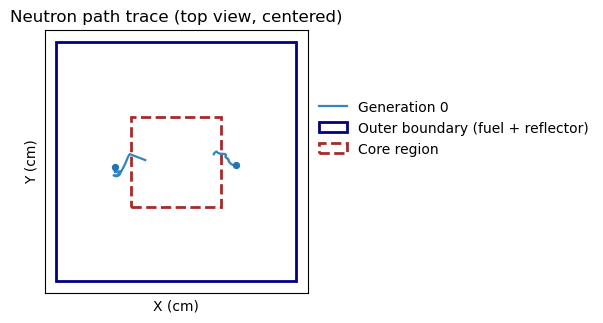

In [14]:
# Build Reactor
rebuild_core()
refls_material = build_reflector_nuclides("graphite")
Lscale = 4.0                            # number of lattices across
lattice_width = 12.0                    # cm
a_core = Lscale*lattice_width           # core size
thickness = 40.0                        # cm
set_geometry(a_core, thickness) 

ks = plot_path_trace_generations_xy()

**Figure 1:** A 2D "top-view" projection of neutron paths for a single Monte Carlo realization with 2 initial neutrons and 3 subsequent generations with a light water reflector. The inner dashed square shows the core and the outer solid square the boundary of the reflector. Coloured tracks indicate the random walks of generations 0–3: paths ending inside the fuel correspond to fission captures that spawn the next generation, paths terminating in the reflector may represent capture or a numerical cutoff, and paths exiting the outer boundary correspond to neutron leakage. This illustrates how the simulation treats fission, absorption, and leakage events in the model geometry.

#### Neutron Energy at Birth

A U-235 fission gives birth to neutrons which are initially quite fast ("velocity about $10^9\ \mathrm{cm/sec}$ or energy above $1\ \mathrm{MeV}$") [17]. 

To model the energy at birth of these neutrons, we use the *Watt Distribution* which accurately represents the energy spectrum of neutrons that are found in experimental data for U-235 fission.


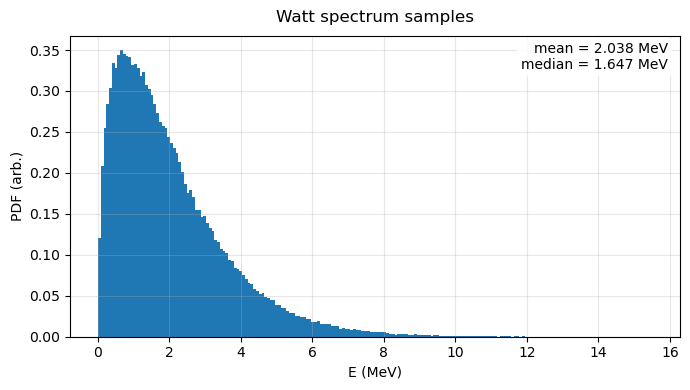

In [15]:
quick_check_watt()

**Figure 2: Histogram of energy samples generated by the Watt function and assigned to each neutron with a sample size of 20,000.** We obtain a mean of ~2.03 MeV and a median of ~1.63 MeV and we can see that this matches with what we have from the figure that most of the neutrons are born around the ~1-2 MeV range with a long tail going up to ~12.5 MeV which matches well with experimental data [18].

#### Discussion

Figures 1 and 2 establish the two core ingredients of our transport model, namely that neutrons execute a random walk through a two-region cubic-shaped reactor and are removed by one of three outcomes: fission in the core (which seeds the next generation), absorption (in the core or reflector), or leaking out from the reflector and into what is effectively a vacuum. New neutrons are born fast, with MeV-scale energies sampled from the Watt distribution, so any fission in later generations will depend on how efficiently scattering in the core and reflector slows the neutrons down before they are lost. This motivates the incorporation of energy-dependent cross sections due to fission and capture probabilities varying strongly across the energy spectrum. The same geometric path can thus correspond to very different reaction likelihoods depending on the neutron's energy history. The next section will therefore introduce the energy-dependent cross-section models used to connect moderation and leakage to changes in $k$.


### How Do Cross Sections Depend on Neutron Energy?

**$\sigma$ in Fuel vs Energy**

To connect the fast fission-birth energies from Figure 2 to the outcomes seen (roughly) in Figure 1, we next need to investigate the energy dependence of the underlying nuclear data used by the model. As shown by Figure 2, Neutrons are born fast with high energy (MeV) and the microscopic cross sections $\sigma(E)$ of the materials used in the reaction will depend on  this energy. A simple explanation is that "neutrons are more likely to collide with certain nuclei when they are moving slowly than when they are fast" [19]. Hence, at large energies and therefore at large speeds, the microscopic cross sections of capture and fission should be reduced compared to lower energies. As the amount of fission (and therefore $k$) depends on the fission microscopic cross section for U-235, any change that shifts the neutron energy, or changes how often collisions occur before absorption or leakage, can change $𝑘$. To highlight this relationship, we will compare key fuel microscopic cross sections vs energy to show how the balance between fission and capture cross sections differ across the energy spectrum.

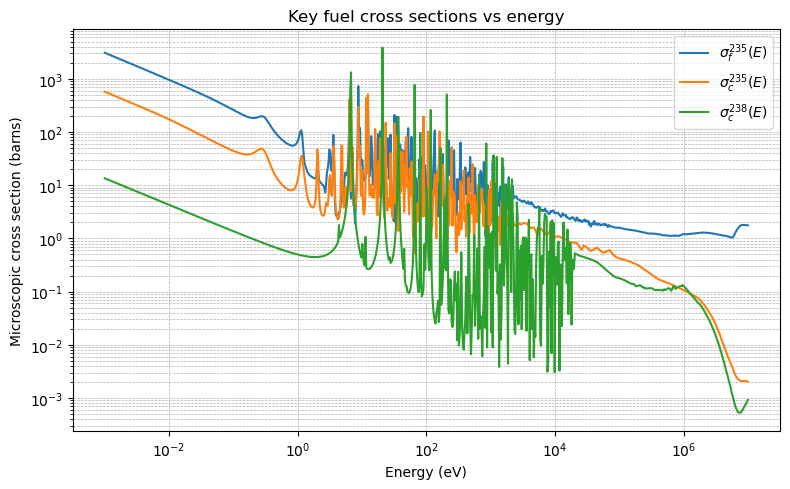

In [16]:
# Build Reactor
rebuild_core()
Lscale = 4.0                            # number of lattices across
lattice_width = 12.0                    # cm
a_core = Lscale*lattice_width           # core size
thickness = 40.0                        # cm
set_geometry(a_core, thickness) 

plot_fuel_xs_energy()

**Figure 3: Key microscopic cross sections for the fuel vs neutron energy.**  The curves show energy-dependent interaction likelihoods (in barns) for the dominant fuel reactions which are used to build reaction probabilities. The log-log axes emphasize how strongly these processes vary with energy. To the left is the thermal range ($<0.5$) eV where the fission and capture cross sections for U-235 are relatively large. In the middle is the resonance range (around $1$ to $10^5$ eV) where the capture cross sections become comparatively more important, especially with U-238 where we can see a large span of spikes in its microscopic capture cross section $\sigma_c^{238}(E)$, resulting in peaks where it is higher than U-235 fission. In the fast range ($>10^5$ eV), we can see that the cross sections become more stable with capture dropping significantly after $10^6$ eV. Nevertheless, the fission cross section is also generally quite low in comparison to thermal levels so inducing the energy of fast neutrons to drop to the thermal range (i.e. thermalization) through the use of moderators plays an important role in increasing $k$.

**Core Reaction Probabilities vs. Energy**

Since each collision outcome is sampled in proportion to the energy-dependent macroscopic reaction rates of the fuel, the same neutron trajectory can lead to different outcomes depending on its energy at interaction. We will therefore convert the cross sections into per-collision outcome probabilities for the baseline core composition, making clear which processes dominate at different energy scales and why shifts in the energy spectrum can change $k$.

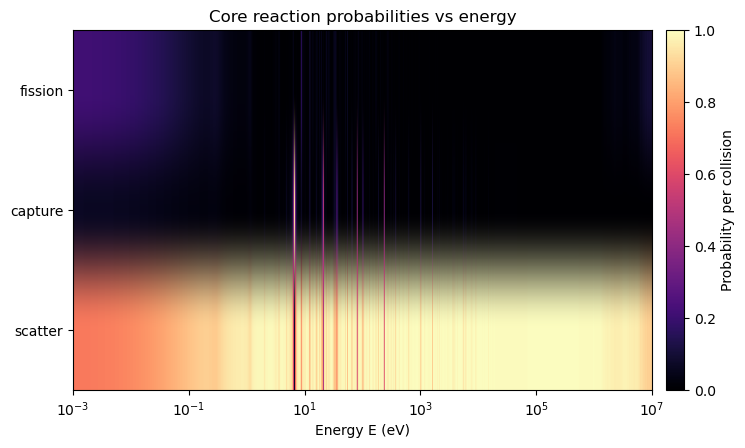

In [17]:
# Build Reactor
rebuild_core()
Lscale = 4.0                            # number of lattices across
lattice_width = 12.0                    # cm
a_core = Lscale*lattice_width           # core size
thickness = 40.0                        # cm
set_geometry(a_core, thickness) 

plot_core_reaction_probabilities()

**Figure 4: Per-collision reaction outcome probabilities vs neutron energy for the core region.** This heatmap shows the conditional probability that a neutron undergoing an interaction at energy E results in a scatter, capture, or fission (colour scale = probability per collision). Dark regions indicate the outcomes that are extremely unlikely at that energy level while bright regions indicate outcomes that dominate the interaction space. This figure summarizes the physical story implied by Figure 3 where at low energies, fission can compete while across much of the intermediate-to-high energy range, scattering tends to dominate, with absorption (fission or capture) being much less likely per collision (although with spikes at resonance due to brief peaks of microscopic cross sections).

#### Discussion

Figures 3 and 4 establish the mechanism by which materials can influence $k$. From Figure 1, we see how geometry affects how long neutrons remain in the system, but the energy history determines whether those interactions are mostly scatters or terminal absorption events. Because scattering dominates across a wide energy range reflectors and moderatiors primarily act by altering how many scattering opportunities occur before leakage or by shifting neutrons into energy ranges where the probability of fission is higher. With this energy-dependent framework established for our model, our next step would be to select baseline parameters such as core moderation and generation choice before resolving our main research question.

### Core Moderation + Generational Stability of $k$

**Which Material is Best Suited for Moderating the Core?**

Before examininng reflector type and thickness in detail, it is important to first fix a baseline material for moderating the core of our reactor model. The core moderator controls how quickly fission neutrons slow down and therefore how strongly the energy-dependent fission and capture cross sections are sampled. We saw from Figure 4 that at very high energies, scattering dominates, so moderating the neutrons as soon as it is born in the core, is vital in moving $k$ closer to criticality. To justify the choice used in the remainder of this study, we compare the estimated multiplication factor $k$ for three plausible core moderators (which are also used in the reflector), namely graphite, light water, and heavy water as well as an unmoderated "pure fuel" core across a range of reflector materials while holding thickness fixed (except for the no reflector case) to isolate how the core itself sets the overall level of $k$ and how much "headroom" there is for different reflector parameters to improve it.

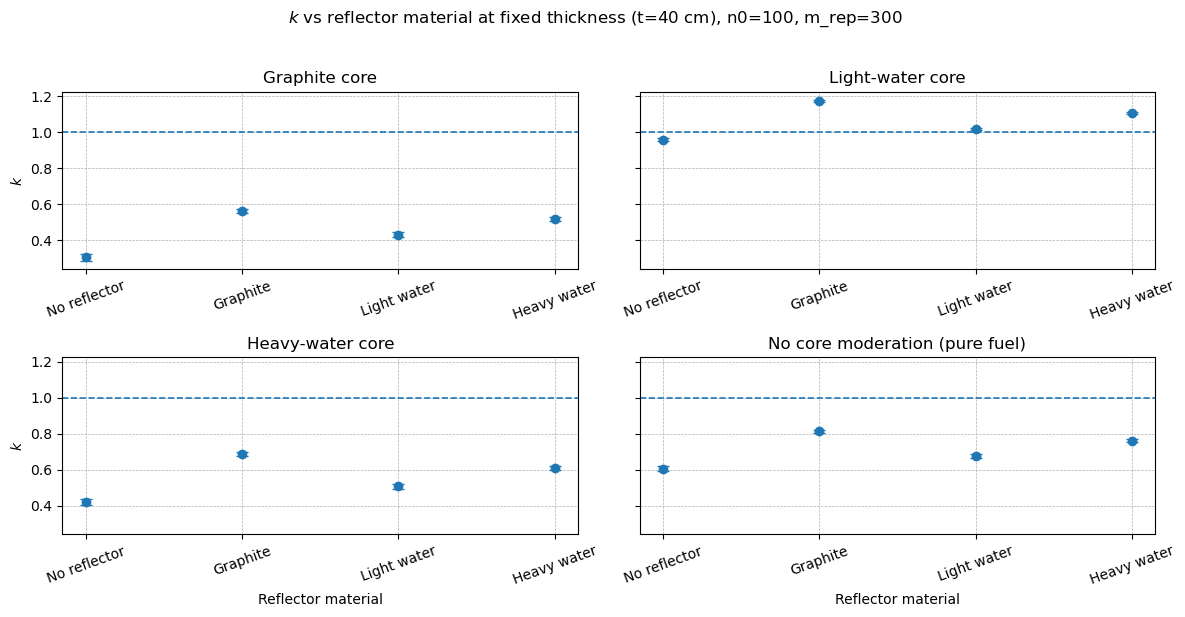

In [18]:
# Build Reactor
rebuild_core()
Lscale = 4.0                            # number of lattices across
lattice_width = 12.0                    # cm
a_core = Lscale*lattice_width           # core size
thickness = 40.0                        # cm

plot_k_by_core_mod(
    fuel_side_cm=a_core,
    thickness_cm=thickness,
    gen=2,
    n0=100,
    m_rep=300,
    vf=0.40
)

**Figure 5: Multiplication factor $k$ with different core moderators.** Mean $k$ is shown for a fixed thickness $t=4\ \mathrm{cm}$ as the reflector material is varied (no reflector, graphite, light water, heavy water). Each panel corresponds to a different material choice for core moderation choice, again between graphite, light water, and heavy water, or a pure-fuel core. This comparison serves to isolate how the baseline core spectrum changes the absolute value of $k$ for different reflector types as well as with no reflector at all. Since a light water core clearly yields the highest $k$ among our choices while still exhibiting clear sensitivity to reflector choice, light water will be adopted as the default core moderator for subsequent studies on parameters affecting $k$. 

**How Does $k$ Stabilize Over Generations?**

Now that a baseline core moderator has been chosen, the next step is to define a consistent generation to estimate $k$ for and to use this consistently throughout the remainder of the investigation rather than averaging across generations (which complicates uncertainty calculations). In this model, $k$ can vary with generation due to finite-sample noise and early discrepancies caused by the inital source, while very late generations can become dominated by a shrinking subset of surviving chains. To examine this trend, we will reduce the size of the core region to just two lattices (i.e. `Lscale = 2.0`) because, while having a larger core increases the chances of fission (and therefore $k$), it also increases the standard error of $\langle k\rangle$ for each generation due to more variability in neutron outcomes. As a result, if we simulate enough Monte Carlo runs, it is highly likely that almost all the generations will have similar survival rates but with a larger range of uncertainty which is detrimental to our purposes of finding the most stable generation. However, we still keep the thickness at 40 cm (on each side) to reduce leakage and give the neutrons more chances to go back to the core. After running the simulation, we will select a single reference generation $g^*$, the earliest generation for which $\langle k\rangle$ shows no statistically significant drift and the standard error is near-minimal while the survival fraction remains high.

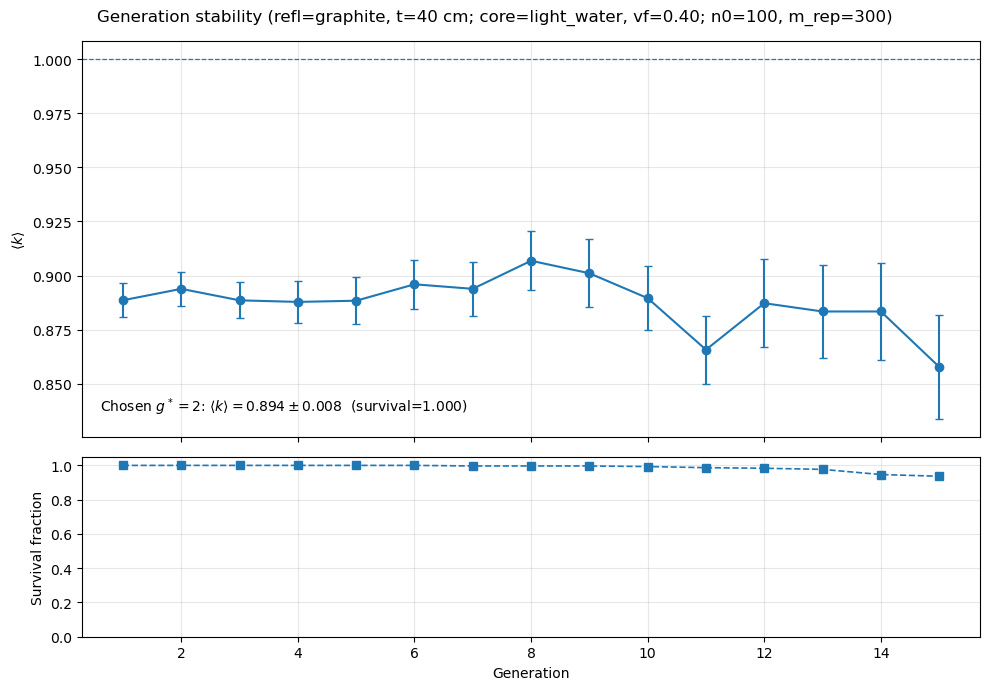

In [19]:
# Build Reactor
rebuild_core()
Lscale = 2.0                            # number of lattices across
lattice_width = 12.0                    # cm
a_core = Lscale*lattice_width           # core size
thickness = 40.0                        # cm

plot_k_stability_multipanel(
    n0=100, max_gen=15, m_rep=300,
    fuel_side_cm=a_core,
    reflector_thickness_cm=thickness,
    reflector_material="graphite",
    core_mod="light_water",
    vf=0.40
)

**Figure 6: Generation-to-generation behaviour of $\langle k\rangle$ and survival fraction.** The top panel shows the conditional mean $\langle k\rangle$ at each generation with standard error bars, computed only over Monte Carlo realizations whose fission chain survives to that generation. The bottom panel shows the corresponding survival fraction (proportion of runs that reach each generation). The chosen reference generation $g^*$ is defined as the earliest generation with near-minimal uncertainty to avoid late-generation survivor bias while not being $g=1$ so as to reduce sensitivity to the initial parent generation.

#### Discussion

Figure 6 shows that, for this representative near-critical configuration, our estimate of $\langle k\rangle$ is broadly consistent across the early generations, while the survival fraction remains close to unity before dropping at later generations as more fission chains terminate. Because uncertainty grows and survivor bias becomes increasingly important at a high generation number, later points are less reliable as a basis for further investigations. We will therefore adopt $g^*=2$ as the reference generation as it is early enough to avoid conditioning on a small surviving subset. In the remainder of this study, all reported multiplication factors $k$ are from generation 2 ($g^*=2$). With our measurement choice now fixed, the next section will perform our main sweep of reflector materials and thickness to quantify how each parameter alters $k$.

### How Do Different Reflector Materials and Thicknesses Influence $k$?

We can now address the main question of this investigation: how reflector material and thickness change the multiplication factor $k$. In the following studies, we hold the core composition and geometry constant and vary only the reflector material and thickness, estimating $k$ from many independent Monte Carlo runs at each point. This produces a direct comparison of reflector performance. After mapping $k$ for each material, we then interpret the trends using simple outcome tallies (fission vs absorption vs leakage) to distinguish whether changes in $k$ are primarily driven by reduced leakage, increased moderation, or additional capture.

**$\langle k\rangle$ vs Thickness per Material**

One of the central measurements in this investigation is how $k$ changes as the reflector is made thicker. For each reflector material, we sweep through a range of values for thickness while holding all of the other parameters constant and compute $k$ from many independent Monte Carlo runs at each thickness. Plotting $k$ as a function of $t$ provides a direct measure of reflector effectiveness, revealing both the relative ranking of materials and whether the benefit of added thickness saturates once leakage has been substantially reduced.

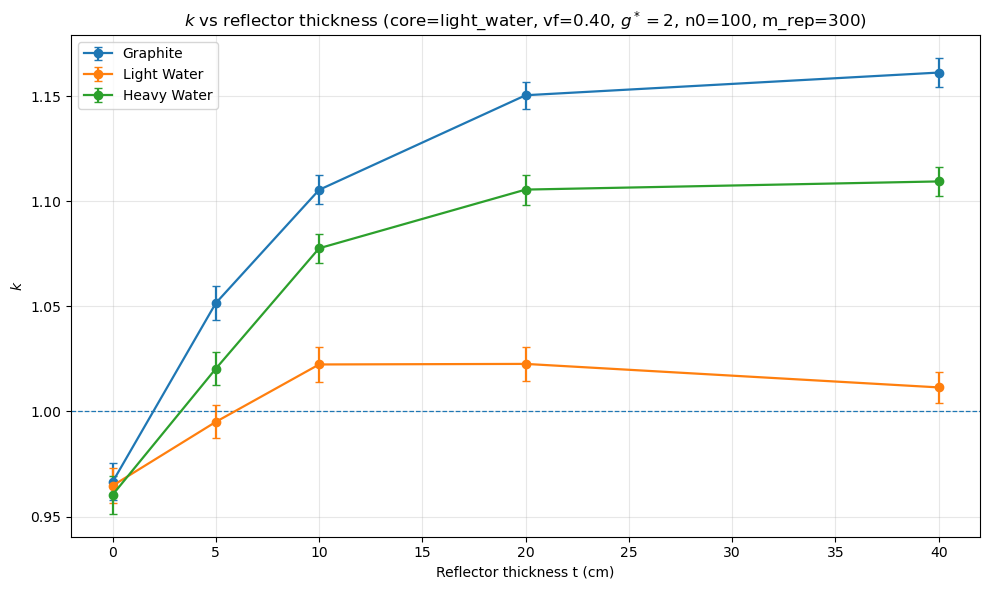

In [20]:
# Build Reactor
rebuild_core()
Lscale = 4.0                            # number of lattices across
lattice_width = 12.0                    # cm
a_core = Lscale*lattice_width           # core size

results = sweep_k_vs_thickness(
    thicknesses_cm=(0, 5, 10, 20, 40),
    core_mod="light_water",
    vf=0.40,
    g_star=2,
    n0=100,
    m_rep=300,
    fuel_side_cm=a_core
)

**Figure 7: Mean multiplication factor <k> as a function of reflector thickness for each material.** For all three reflectors, <k> increases rapidly between t = 1 and t = 5 cm. However, depending on the material, the growth rate begins to level off with light water saturating the fastest around ~10 cm while graphite and heavy water continue to grow until ~20 cm. This is most likely due to the comparatively high scattering cross section of hydrogen which results in a shorter mean free path for the neutrons in a reflector made of light water resulting in less leakage. Increasing reflector thickness generally increases $k$, presumambly due to the reduction of leakage but with diminishing returns at larger $t$ as leakage reduction starts to be non-factor in neutron outcomes. 

**Uncertainty vs Thickness per Material**

To confirm that the trends we have observed in our previous figures are statistically significant, it is important to study how the sampling uncertainty varies with reflector thickness and material. For example, as we've seen in Figure 6, configurations with fewer surviving fission chains and stronger leakage, produce noisier estimates. To quantify this, we will compute the standard error of $k$ at each thickness and plot the relative uncertainty (standard error divided by the mean) as a function of $t$ for each reflector material. This provides us with a simple diagnostic to find which values of $t$ the simulation converges nicely to and whether additional increase in reflector size would be required to distinguish materials reliably.

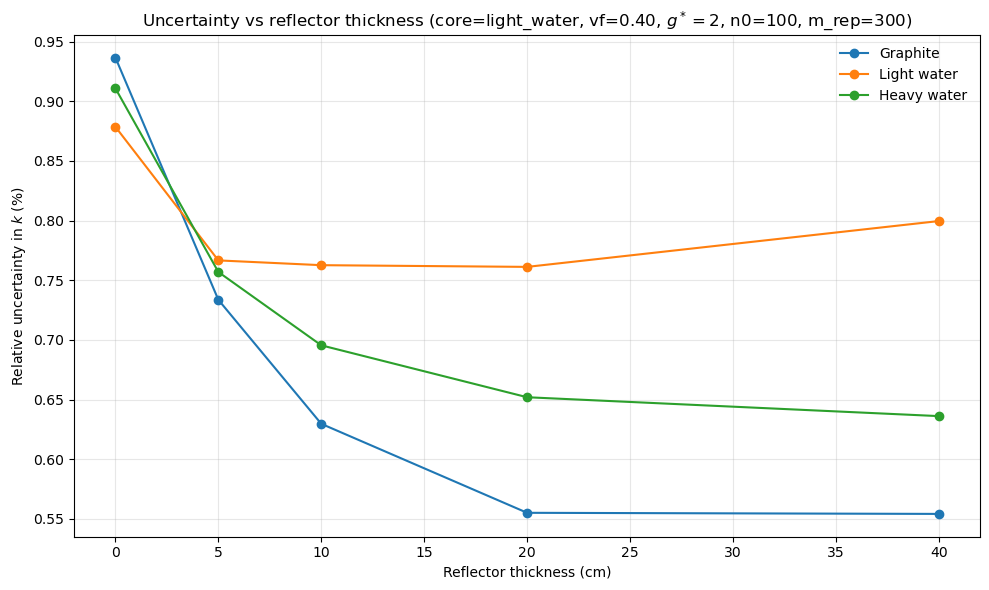

In [21]:
# Build Reactor
rebuild_core()
Lscale = 4.0                            # number of lattices across
lattice_width = 12.0                    # cm
a_core = Lscale*lattice_width           # core size

unc = plot_uncertainty_vs_thickness(
    thicknesses_cm=(0, 5, 10, 20, 40),
    core_mod="light_water",
    vf=0.40,
    g_star=2,
    n0=100,
    m_rep=300,
    fuel_side_cm=a_core
)

**Figure 8: Relative statistical uncertainty in the estimated multiplication factor $\langle k\rangle$ as a function of reflector thickness per materials.** Throughout the sweep, the relative uncertainty remains in the approximately the percent-scale range, with highest uncertainty at $t=0$, most likely due to strong leakage, and generally improves once a reflector is present. The relative uncertainty of the different materials should be compared with the size of the observed differences in $k$ before drawing conclusions about material rankings. These error bars describe Monte Carlo sampling uncertainty, not systematic uncertainty in the physical model.

**Histogram of $\langle k\rangle$ Frequency per Material**

In addition to reporting the mean $k$ and its uncertainty vs thickness, it would be useful to examine the full distribution of $k$ obtained from independent Monte Carlo runs. Different configurations with similar mean $k$ can still behave differently where one may produce a tight, Gaussian-like spread of outcomes, while another may be dominated by occasional low-$k$ realizations or early extinctions. To visualize this variability directly, we plot histograms of the sampled $k$ values for each reflector material at a fixed representative thickness, $t=40\ \mathrm{cm}$, while using the same core configuration as in the previous sweeps.

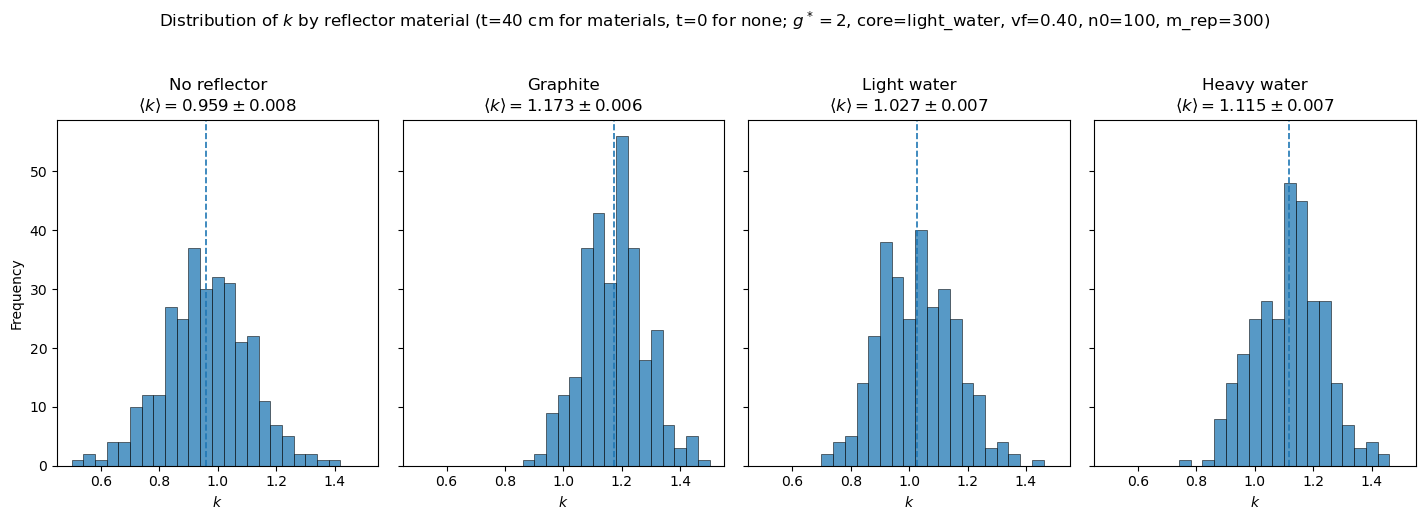

In [22]:
# Build Reactor
rebuild_core()
Lscale = 4.0                            # number of lattices across
lattice_width = 12.0                    # cm
a_core = Lscale*lattice_width           # core size
thickness = 40                          # cm

plot_k_histograms_by_reflector_material(
    thickness_cm=thickness,
    fuel_side_cm=a_core,
    g_star=2,
    n0=100,
    m_rep=300,
    core_mod="light_water",
    vf=0.40,
    bins=25
)

**Figure 9: Histograms of the average multiplication factor k for the three reflector materials.** The dashed vertical line in each panel marks the sample mean $\langle k \rangle$. Graphite has a mean $k$ of 1.164 which is higher than that of light water and heavy water, which suggests that a reflector made of graphite may have a slightly greater tendency of causing the fission reaction to become supercritical compared to one made of heavy water or light water. Heavy water has a smaller mean $k$ compared to graphite at 1.101, while light water, having a stronger left tail than the other two, has a mean $k$ of 1.017 which is around 0.1 less than heavy water. Our model with no reflector at all achieves a mean $k$ of 0.974 so not quite at critical levels which proves the effectiveness of reflectors as with the configurations we have chosen at thickness $t=40\ \mathrm{cm}$, all materials are at critical levels with $\langle k\rangle\approx 1$ so each one has a self-sustaining fission reaction on average.

#### Discussion

Across all reflector materials, increasing thickness generally increases $k$, consistent with the basic reflector role in reducing leakage and increasing the probability that fission-born neutrons return to the core and induce additional fissions. The relative ordering between the materials reflects the trade-off between scattering and absorption where more effective reflectors are those that return neutrons without introducing large absorption.

The uncertainty plot shows that the sampling precision remains at the ~0.5-1% level across the sweep, with the largest relative uncertainty at $t=0$ where leakage is highest. This is expected as when most neutrons leak out, outcomes are dominated by "failures" (no fission). Adding a reflector raises fission probability and reduces extinctions, which tightens the estimate. 

The histogram of $k$ at a representative thickness adds a complementary view of the same result. Rather than showing only the mean and standard error, it shows the full distribution of outcomes across independent realizations. The differences between reflectors now appear primarily as a systematic shift in the centre of the distribution (and not just a few outliers), and the degree of overlap indicates how confidently the materials can be distinguished at this thickness where graphite is more probable to have super-critical values of $k$ and light water being more probable to have sub-critical values with heavy water being in the middle ground. Importantly, this is not driven by a few extreme runs as the differences in the distribution for $\langle k\rangle$ for each material is statistically significant due to low standard errors which do not overlap with the other materials. This suggests a systematic difference in the likelihood of neutron outcomes (e.g. increased reflector absorption and/or less effective return-to-core) rather than statistical fluctuations.

Lastly, we want to mention that, as seen in Figure 5, light water works best among the materials as a core moderator and produces the largest $k$ which is in contrast to its results here as a reflector where it performs comparatively poorly (at least when it comes to maximizng $k$). An explanation would be is that fission does *not* occur in the reflector. Furthermore, hydrogen has a comparatively large thermal capture cross section in comparison to deuterium and carbon-12. It also has high scattering (again shorter mean free path) so neutrons can spend many collisions in the reflector without ever undergoing fission and possibly get absorbed by hydrogen rather than returning to the core. Graphite and heavy water by contrast have lower absorption and scattering and thus a larger mean free path for the neutrons so they have a higher probability of scattering neutrons back into the core without absorbing them in the reflector, which is why they often give higher $k$ as reflector materials.

### A Breakdown of Outcomes

Now that we have addressed our main research question and established how reflector materials and thickness affect $k$, our final step will be to expalin why these changes occur in our model. A reflector can increase $k$ by reducing leakage, but it can also change a neutron's energy with each collision, shifting the balance between the energy-dependent cross sections (particularly in the epithermal/resonance window). Each neutron ultimately ends in one of a small number of terminal outcomes, either it undergoes fission in the core, is absorbed in the core, is absorbed in the reflector, or leaks out of the reactor. To separate leakage effects from absorption losses, we repeat the simulation and tally the fraction of source neutrons that end in each outcome as a function of reflector thickness and we do this for each material. This provides a clear interpretation of $k$ performance for each material by showing whether changes in $k$ are primarily driven by reduced leakage, increased fission probability, or increased absorption.

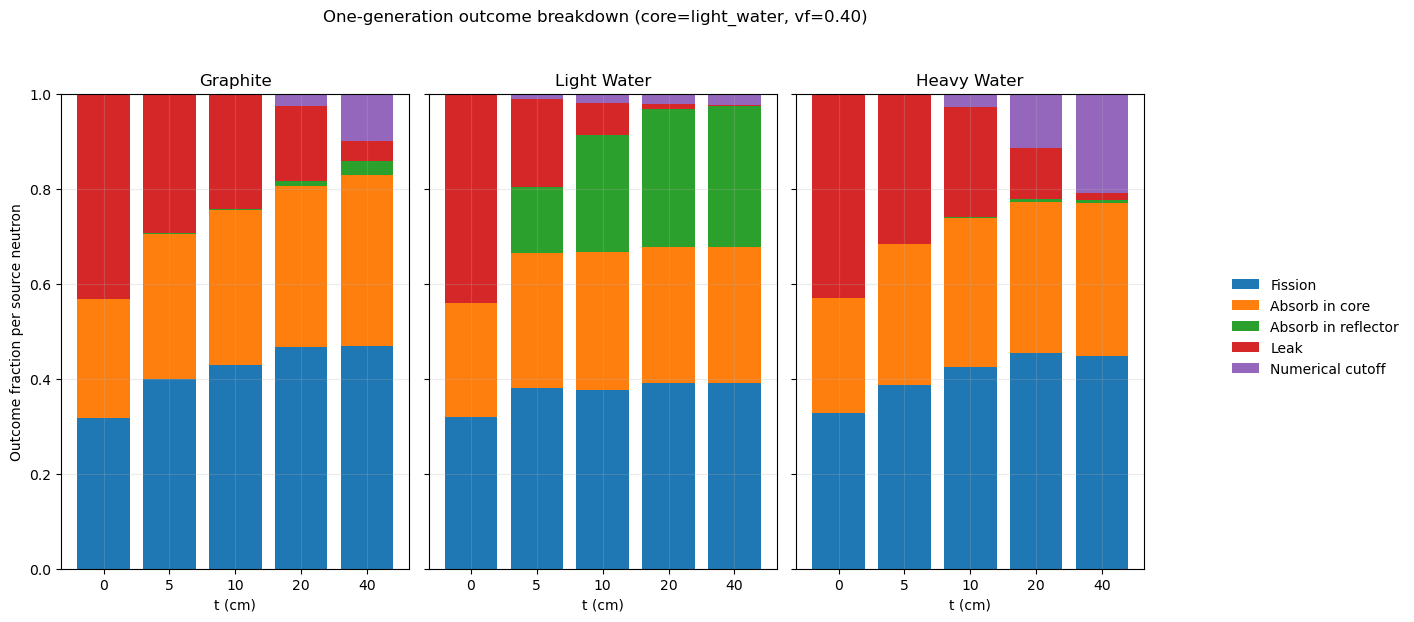

In [23]:
# Build Reactor
rebuild_core()
Lscale = 4.0                            # number of lattices across
lattice_width = 12.0                    # cm
a_core = Lscale*lattice_width           # core size

plot_outcome_breakdown(
    thicknesses_cm=(0, 5, 10, 20, 40),
    reflector_mats=("graphite", "light_water", "heavy_water"),
    core_mod="light_water",
    vf=0.40,
    n_hist=8000,
    fuel_side_cm=a_core,
    seed=1
)

**Figure 10: Terminal outcomes per initial neutron at different reflector thicknesses.**
For each reflector material, neutrons begin at uniformly sampled positions **inside the core** with Watt-distributed birth energies. Each history ends in core fission, core capture, reflector capture, leakage, or **numerical cutoff** (shown separately, rather than incorrectly counted as absorption). The five stacked fractions sum to one in each case. With the corrected source sampler and explicit cutoffs, regenerate this plot before making quantitative claims about how the individual fractions vary with thickness.


#### Discussion

The terminal-outcome breakdown can help explain changes in the multiplication statistic through competition among fission, capture, and leakage. A thicker reflector may return neutrons to the core, but it also permits further scattering and capture. Numerical cutoffs are not physical absorptions and must be inspected separately; if their fractions are appreciable, increase the collision caps and repeat the experiment. The effect and relative ranking of reflector materials should be assessed from the **newly generated** Figure 10 rather than the invalid original figure.


### Summary of Results

This investigation used a simplified Monte Carlo transport model to estimate the multiplication factor $k$ of a U-235 system with a homogenized core and an external reflector. Neutrons were born from fission with a Watt spectrum and tracked through a two-region cube geometry until they terminated by either inducing a fission in the core, being absorbed (in the core or reflector), or leaking through the boundary. Furthermore, energy-dependence was introduced through real-world nuclear data. 

To ensure consistent comparisons, a baseline core configuration was selected and a single reference generation $g^*=2$ was adopted for reporting $k$, rather than averaging across generations. This avoids ambiguous cross-generation uncertainty and reduces sensitivity to late-generation survivor effects. With these choices fixed, the reflector study focused on how material and thickness alter the balance between leakage and absorption, and therefore the probability that a fission-born neutron produces a subsequent fission event.

The outcome breakdown provides an additional diagnostic of leakage, physical absorption, and fission; its quantitative conclusions should be checked after regenerating Figure 10 with the corrected source positions. This is consistent with reflectors improving neutron economy primarily by returning neutrons to the core. The improvement is not unbounded, however. At larger thicknesses, additional absorption, in the reflector *and* the core, competes with the leakage reduction. This limits gains and produces saturation-like behaviour. Differences between reflector materials follow from this same tradeoff. Thus, the most effective reflector is the one that reduces leakage efficiently (via scattering/return) without introducing a large absorption penalty due to higher capture cross sections.

#### Discussion of the Physical Modelling

Interpreting the results in terms of the physics model, reflectors influence $k$ through two coupled mechanisms. First, they change the spatial fate of neutrons by reducing escape probability. Neutrons that would have leaked in an unreflected system undergo additional interactions in the reflector and can re-enter the core, increasing the chance of a productive fission outcome. Second, because cross sections are energy dependent, those additional interactions also change the energy history of neutrons, shifting the competition between fission and capture (notably U-238 capture in the resonance window in this model from Figure 3). Figure 10 is intended to summarize these competing mechanisms, while distinguishing actual absorption from numerical termination.

Nevertheless, it is important to emphasize that this model remains an imperfect representation: the geometry is still highly idealized, core materials are homogenized, and scattering is purely elastic. As a result, the absolute values of $k$ (even though we managed to tweak it into reaching criticality) should not be interpreted as yet predictive of a real assembly. However, the qualitative trends are meaningful within the model as reflector performance emerges from a competition between leakage suppression and absorption, and energy dependence provides a clear pathway for moderation to influence $k$.

#### Conclusion 

Within this simplified two-region Monte Carlo framework with energy-dependent cross sections, reflector materials and thickness influence the multiplication factor $k$ primarily by reshaping the terminal outcome balance of fission-born neutrons. Increasing reflector thickness reduces leakage and increases the fraction of neutrons that return to the core and induce fission, thereby increasing $k$. The improvement saturates when additional reflector thickness yields diminishing leakage reduction and absorption losses become comparatively more important. Material differences are explained by the same mechanism where reflectors that provide strong return-to-core scattering with low absorption produce the largest net gain in $k$.

## Acknowledgements

Generative AI was used as a sounding board for exploring ideas about which parameters to vary for phase space investigation. It was also used to help find references for information on the materials and energy-dependent cross sections used for real nuclear reactors.

The poster by Rohith Rajmohan, *Investigating the Impact of Neutron Yield, Density and Moderators on the Multiplication Factor in U-235 Fission*, included a reference which I have also used here [3].

## References

1. http://large.stanford.edu/courses/2024/ph241/mukunda1/

2. https://nuclear.mcmaster.ca/resources/how-does-it-work-2/controlling-fission/

3. https://en.wikipedia.org/wiki/Neutron_cross_section

4. https://ocw.mit.edu/courses/22-06-engineering-of-nuclear-systems-fall-2010/6f1f0d20f03babacef32b9a7ac9e3a33_MIT22_06F10_lec06b.pdf 

5. https://world-nuclear.org/information-library/Nuclear-Fuel-Cycle/Conversion-Enrichment-and-Fabrication/Fuel-Fabrication

6. https://clive.semmens.org.uk/Energy/FreePath.html

7. https://indico.cern.ch/event/145296/contributions/1381141/attachments/136909/194258/lecture24.pdf

8. https://docs.openmc.org/en/v0.8.0/pythonapi/generated/openmc.stats.Watt.html

9. https://arxiv.org/html/2402.09454v1

10. https://www.oecd-nea.org/janisweb/tree/N/'ENDF/B-VIII.0'/SIG

11. https://dspace.mit.edu/bitstream/handle/1721.1/74136/22-05-fall-2006/contents/lecture-notes/lecture04.pdf

12. https://www.nndc.bnl.gov/endfdocs/ENDF-102-2023.pdf

13. https://jaschwartz.net/journal/interpolating-log-log.html

14. https://www.nrc.gov/docs/ML1214/ML12142A083.pdf

15. https://en.wikipedia.org/wiki/Bernoulli_distribution

16. https://en.wikipedia.org/wiki/Slab_method

17. https://world-nuclear.org/information-library/nuclear-fuel-cycle/introduction/physics-of-nuclear-energy

18. https://www.sciencedirect.com/science/chapter/monograph/pii/B9780080405193500081

19. https://cms.cern/news/what-do-we-mean-cross-section-particle-physics

20. https://poco.entegris.com/content/dam/poco/resources/reference-materials/brochures/brochure-graphite-properties-and-characteristics-11043.pdf

21. https://www.sfu.ca/phys/demos/demoindex/fluids/fl2b/density.html

22. https://www.wikidoc.org/index.php/Heavy_water

23. https://en.wikipedia.org/wiki/Uranium_dioxide

24. https://en.wikipedia.org/wiki/Uranium-235

25. https://en.wikipedia.org/wiki/Uranium-238

## Appendix 1: Code validation

### A1.1: Sanity Checks

In [24]:
def test_elastic_scatter_energy_bounds(n=20000, E0=2e6):
    # bounds: alpha*E <= E' <= E
    for A in [1.0, 2.0, 12.0]:
        alpha = ((A - 1.0) / (A + 1.0))**2
        Emin = alpha * E0
        Eout = []
        ux, uy, uz = 0.0, 0.0, 1.0
        for _ in range(n):
            ux, uy, uz, E1 = elastic_scatter_update(ux, uy, uz, E0, A)
            Eout.append(E1)
        Eout = np.array(Eout)

        assert Eout.min() >= Emin - 1e-6*E0, (A, Eout.min(), Emin)
        assert Eout.max() <= E0 + 1e-12*E0, (A, Eout.max(), E0)

    # moderation ordering via mean energy loss per collision
    def mean_Eprime(A):
        ux, uy, uz = 0.0, 0.0, 1.0
        vals = []
        for _ in range(n):
            ux, uy, uz, E1 = elastic_scatter_update(ux, uy, uz, E0, A)
            vals.append(E1)
        return np.mean(vals)

    mH = mean_Eprime(1.0)
    mD = mean_Eprime(2.0)
    mC = mean_Eprime(12.0)
    assert mH < mD < mC, (mH, mD, mC)

    print("PASS: elastic scatter energy bounds + moderation ordering (H > D > C).")

def test_boundary_beats_collision():
    # Put neutron inside the reflector, just outside the core; aim toward core.
    assert half_outer > half_fuel + 0.5, "Test requires reflector thickness > 0.5 cm"
    x = half_fuel + 0.5
    y = 0.0
    z = 0.0
    ux, uy, uz = -1.0, 0.0, 0.0

    d_bnd, event = next_boundary_distance(x, y, z, ux, uy, uz, region="reflector")
    assert event == "to_fuel"
    assert np.isclose(d_bnd, 0.5), (d_bnd, event)
    # With a hypothetical collision 1 cm away, geometry wins (0.5 < 1.0).
    assert d_bnd < 1.0

    # Aim outward: the next boundary must instead be a leak.
    d_out, event_out = next_boundary_distance(x, y, z, 1.0, 0.0, 0.0, region="reflector")
    assert event_out == "leak" and d_out > 0

    print("PASS: inward rays reach the core; outward rays leak.")


def test_numerical_cutoff_is_not_capture():
    set_geometry(48.0, 10.0)
    global current_r_material
    current_r_material = "graphite"
    rebuild_core()
    _, _, _, status = move_with_trace(0.0, 0.0, 0.0, sample_watt_u235(),
                                     max_fuel_collisions=0)
    assert status == "numerical_cutoff", status
    print("PASS: collision cutoff is distinguished from physical capture.")

def test_material_ranking_quick(n0=100, gen=2, m_rep=100, core_mod="light_water",
                                max_reflector_collisions=200, max_fuel_collisions=200,
                                seed=1):
    """Compare materials using a fixed seed and configurable numerical cutoffs."""
    for i, mat in enumerate(["graphite", "light_water", "heavy_water"]):
        np.random.seed(seed + i)
        k_mean, k_err = estimate_k_for_material(
            mat, core_mod=core_mod, n0=n0, gen=gen, m_rep=m_rep,
            max_reflector_collisions=max_reflector_collisions,
            max_fuel_collisions=max_fuel_collisions
        )
        print(f"{mat:12s}  k(gen={gen}) = {k_mean:.4f} ± {k_err:.4f}")

def plot_xs_sanity_check():
    E = np.logspace(-5, 7.3, 1200)  # eV, ~1e-5 to ~2e7

    # evaluate (barns)
    u235_f = np.array([sig_f_U235(e) for e in E])
    u235_c = np.array([sig_c_U235(e) for e in E])
    u238_c = np.array([sig_c_U238(e) for e in E])
    u238_f = np.array([sig_f_U238(e) for e in E])

    h_cap  = np.array([sig_c_h1(e) for e in E])   # example moderator capture
    c_cap  = np.array([sig_c_c12(e) for e in E]) # example graphite capture

    plt.figure(figsize=(9, 6))
    plt.loglog(E, u235_f, label="U-235 fission (MT18-ish)")
    plt.loglog(E, u235_c, label="U-235 capture (MT102-ish)")
    plt.loglog(E, u238_c, label="U-238 capture (resonance-ish)")
    plt.loglog(E, u238_f, label="U-238 fast fission (threshold-ish)")
    plt.loglog(E, h_cap,  label="H capture (core moderator)")
    plt.loglog(E, c_cap,  label="C-12 capture (core moderator)")

    plt.xlabel("Neutron energy E (eV)")
    plt.ylabel("Microscopic cross section σ(E) (barns)")
    plt.title("Sanity check: analytic energy-dependent σ(E)")
    plt.grid(True, which="both", linestyle="--", linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

def free_path_test(nucs, E, n=50000):
    Ss, Sc, Sf, St = macro_xs_from_nuclides(nucs, E)
    d = np.random.exponential(1.0/St, size=n)
    return d.mean(), 1.0/St
    # call
    #mean_d, theory = free_path_test(core_nucs, E=1e3)
    #print("mean sampled d =", mean_d, " theory =", theory)

#### Sensitivity To `max_fuel_collisions` and `max_reflector_collisions`

The main calculations use collision caps of 200 per segment in each region. We compare them with caps of 500 without redefining `move_with_trace()`. The quick test uses matched seeds for each material; independent reruns and uncertainty estimates are needed to determine whether any observed differences are statistically meaningful. The source of finite-cutoff bias is separately identified as `numerical_cutoff` in Figure 10.


In [25]:
rebuild_core()
set_geometry(48.0, 40.0)
test_elastic_scatter_energy_bounds(n=2000)
test_boundary_beats_collision()
test_numerical_cutoff_is_not_capture()
print("Collision caps: reflector=200, fuel=200")
test_material_ranking_quick(max_reflector_collisions=200,
                            max_fuel_collisions=200)


PASS: elastic scatter energy bounds + moderation ordering (H > D > C).
PASS: inward rays reach the core; outward rays leak.
PASS: collision cutoff is distinguished from physical capture.
Collision caps: reflector=200, fuel=200
graphite      k(gen=2) = 1.1091 ± 0.0121
light_water   k(gen=2) = 1.0092 ± 0.0139
heavy_water   k(gen=2) = 1.0769 ± 0.0121


In [26]:
# Repeat the same numerical experiment with larger limits, rather than
# redefining move_with_trace() halfway through the notebook.
# For a quick smoke test, lower n0/m_rep; the published figure sweeps are more costly.
print("Collision caps: reflector=500, fuel=500")
test_material_ranking_quick(max_reflector_collisions=500,
                            max_fuel_collisions=500)


Collision caps: reflector=500, fuel=500
graphite      k(gen=2) = 1.1038 ± 0.0131
light_water   k(gen=2) = 1.0194 ± 0.0126
heavy_water   k(gen=2) = 1.0650 ± 0.0126


In [27]:
# The comparison above uses the larger caps (500/500).


The comparison above is a **sensitivity check**, not evidence that the collision caps have no effect by themselves. Interpret any changes relative to their standard errors; if needed, increase the number of realizations and repeat the same comparison. Because the original appendix redefined the transport function, its previously stored results are not carried over.


### A1.2: Cross Section Calculations

Here we place our method of calculation for macroscopic cross sections using data from [10]. Please note that the model uses a different data source. However, the method of calculation to find the macroscopic cross section from the microscopic cross section data remains the same in the simulation even if the actual values derived here are different.

#### Equation for Mean Free Path $\lambda$
$$\lambda=\frac{1}{\sum}=\frac{1}{N\sigma}\ \text{[6]}$$

where $\sum$ is the macroscopic cross section, $N$ is the atomic density, and $\sigma$ is the microscopic cross section of the material.

#### Mass Density ($\rho$) and Number Density ($N$) For Reflector Material

Graphite (C-12): 
- $\rho=1.9\ \mathrm{g/cm^3}$ (typical bulk density) [18]
- $N=\frac{\rho N_{A}}{A}=\frac{1.9\times6.022\times10^{23}}{12.01}=9.53\times10^{22}\ \mathrm{cm^{-3}}$ 

$N_A$ is Avogadro's constant and $A$ is the atomic mass of the material.

Light Water (H₂O): 
- $\rho=1.0\ \mathrm{g/cm^3}$ (at $20°\mathrm{C}$) [19]
- $N=\frac{\rho N_{A}}{A}=\frac{1.0\times6.022\times10^{23}}{18.02}=3.34\times10^{22}\ \mathrm{cm^{-3}}$

Heavy Water (D₂O): 
- $\rho=1.11\ \mathrm{g/cm^3}$ (at $20°\mathrm{C}$) [20] 
- $N=\frac{\rho N_{A}}{A}=\frac{1.11\times6.022\times10^{23}}{20.03}=3.34\times10^{22}\ \mathrm{cm^{-3}}$

#### Mass Density ($\rho$) and Number Density ($N$) For Fuel

$\mathrm{UO_2}$ has a density of $\rho=10.97\ \mathrm{g/cm^3}$ and a molar mass of $M=270.03\ \mathrm{g/mol}$ [21]. Thus, it has a number density of $$N_{\mathrm{UO_2}}=\frac{\rho N_A}{M}=\frac{10.97\cdot 6.022\cdot 10^{23}}{270.03}\approx 2.45\times 10^{22}\ \mathrm{cm^{-3}}.$$

For a 5% enrichment of uranium, we need the mass of U-235 to be 5% of the uranium and U-238 to be 95%. The atomic mass of U-235 is approximately $M_{235}\approx235.04\ \mathrm{g/mol}$ [22] and U-238 is $M_{238}\approx 238.05\ \mathrm{g/mol}$ [23]. So the fraction of U-235 atoms in uranium is: $$f_{235}=\frac{0.05/M_{235}}{0.05/M_{235} + 0.95/M_{238}}\approx0.05061,$$ and thus the fraction of U-238 atoms is $$f_{238}=1-f_{235}\approx0.9494.$$

Then, since $\mathrm{UO_2}$ has 1 uranium atom and 2 oxygen atoms, $N_{\mathrm{U}}\approx N_{\mathrm{UO_2}}$. Thus, the uranium isotopes' number densities are $$N_{235}=f_{235}N_{\mathrm{UO_2}},\ N_{238}=f_{238}N_{\mathrm{UO_2}}.$$

So we have:
- $N_{235}\approx1.24\times 10^{21}\ \mathrm{cm^{-3}}$
- $N_{238}\approx2.33\times 10^{22}\ \mathrm{cm^{-3}}$.

#### Thermal Neutrons

##### Reflector

**Microscopic Cross Sections ($\sigma$)**

To model graphite, we treat it as mostly C-12 and use the following thermal cross section *scattering* values [3] for our $\sigma_s$:

- Graphite scattering: $$\sigma_s{\text{C-12}}=5\ b$$

- Light water scattering: $$\sigma_s{\mathrm{H_{2} O}}\approx 2\sigma_{s,H}+\sigma_{s,O}=2\times20+4=44\ b$$

- Heavy water scattering: $$\sigma_s{\mathrm{D_{2}O}}\approx 2\sigma_{s,D}+\sigma_{s,O}=2\times4+4=12\ b$$

where $1\ b = 1\times10^{-24}\ \mathrm{cm^2}$.

For *absorption* terms, we have:

- Graphite absorption: $$\sigma_a{\text{C-12}}=2\times10^{-3}\ b$$

- Light water absorption: $$\sigma_a{\mathrm{H_{2} O}}\approx 2\sigma_{a,H}+\sigma_{a,O}=2\times0.2+1\times10^{-4}=0.4001\ b$$

- Heavy water (D₂O) absorption: $$\sigma_a{\mathrm{D_{2}O}}\approx 2\sigma_{a,D}+\sigma_{a,O}=2\times3\times10^{-4}+1\times10^{-4}=7\times10^{-4}\ b$$

Then our *total microscopic cross section* is $$\sigma_t=\sigma_s+\sigma_a.$$

$$\sum_a=(3.34\times10^{22})(7\times10^{-28})=2.338\times10^{-5}\ \mathrm{cm^{-1}}.$$

**Macroscopic Cross Sections $\left(\sum\right)$**

For the macroscopic *scattering* cross sections, we have

- Graphite scattering: $$\sum_s=(9.53\times10^{22})(5\times10^{-24})=0.4765\ \mathrm{cm^{-1}}$$

- Light water scattering: $$\sum_s=(3.34\times10^{22})(44\times10^{-24})=1.470\ \mathrm{cm^{-1}}$$

- Heavy water scattering: $$\sum_s=(3.34\times10^{22})(12\times10^{-24})=0.4008\ \mathrm{cm^{-1}},$$

and for the macroscopic absorption cross sections

- Graphite absorption: $\sum_a=(9.53\times10^{22})(2\times10^{-27})=1.906\times10^{-4}\ \mathrm{cm^{-1}}$

- Light water absorption: $\sum_a=(3.34\times10^{22})(0.4001\times10^{-24})=0.01336\ \mathrm{cm^{-1}}$

- Heavy water absorption : $\sum_a=(3.34\times10^{22})(7\times10^{-28})=2.338\times10^{-5}\ \mathrm{cm^{-1}}.$

Then our *total macroscopic scattering cross sections* for each material are

- Graphite: $$\sum_t=0.4765+1.906\times10^{-4}=0.4767\ \mathrm{cm^{-1}}$$
- Light water: $$\sum_t=1.470+0.01336=1.483\ \mathrm{cm^{-1}}$$
- Heavy water: $$\sum_t=0.4008+2.338\times10^{-5}=0.4008\ \mathrm{cm^{-1}}.$$

**Probabilities per interaction**

In our Monte Carlo, we use the ratio of absorption to total cross section to decide, at each reflector collision/interaction, whether the neutron is absorbed or scattered:

$$\mathrm{P(absorbed)}=\frac{\sum_a}{\sum_t},\ \mathrm{P(scattered)}=\frac{\sum_s}{\sum_t}.$$

- Graphite
$$\mathrm{P(absorbed)}=\frac{1.906\times10^{-4}}{0.4767}\approx0.0004$$
- Light water
$$\mathrm{P(absorbed)}=\frac{0.01336}{1.483}\approx0.009$$
- Heavy water
$$\mathrm{P(absorbed)}=\frac{2.338\times10^{-5}}{0.4008}\approx0.00006$$

##### Fuel

Since this investigation simulates a fission reactor using U-235, we follow the example of typical reactors and use a fuel of uranium enriched to 5%, converted into $\mathrm{UO_2}$ and made into fuel pellets [5].

**Microscopic absorption cross sections**

From thermal neutron data [3], we obtain the following values:

- U-235
    - capture: $\sigma^{235}_{\lambda}\approx 99\ \mathrm{b}$
    - fission: $\sigma^{235}_{f}\approx 583\ \mathrm{b}$
    - total absorption: $\sigma^{\mathrm{235}}_a=583+99=682\times 10^{-24}\ \mathrm{cm^2}$
- U-238
    - total absorption: $\sigma^{\mathrm{238}}_a=2\times 10^{-24}\ \mathrm{cm^2}$ (thermal fission is negligible)
- O-16
    - total absorption: $\sigma^O_a\approx 1\times10^{-4}\ \mathrm{b}=1\times10^{-28}\ \mathrm{cm^2}$
    - we have two O atoms per $\mathrm{UO_2}$ molecule so we effectively have a total of $\sigma^O_a\approx2\times10^{-28}\ \mathrm{cm^2}$ per $\mathrm{UO_2}$

**Macroscopic absorption cross section**

$$\sum_a=N_{235}\sigma^{235}_a+N_{238}\sigma^{238}_a+N_O\sigma^O_a.$$

- U-235 absorption term

$$\sum_{a,235}\approx(1.24\times10^{21})(682\times10^{-24})\approx0.846\ \mathrm{cm^{-1}}.$$


- U-238 absorption term

$$\sum_{a,238}\approx(2.33\times10^{22})(2\times10^{-24})\approx0.0466\ \mathrm{cm^{-1}}.$$

- Oxygen absorption term

$$\sum_{a, O}\approx(2\times2.45\times10^{22})(1\times10^{-28})\approx4.9\times10^{-6}\ \mathrm{cm^{-1}}.$$

- Total absorption term

$$\sum_a\approx0.846+0.0466+4.9\times10^{-6}=0.8926\ \mathrm{cm^{-1}}$$

**Macroscopic fission cross section**

The macroscopic fission cross section $\sum_f$ only involves the fission part of U-235's absorption $$\sum_f=N_{235}\sigma^{235}_f\approx(1.24\times10^21)(583\times10^{-24})\approx0.723\ \mathrm{cm^{-1}}.$$

We can now also see the non-fission absorption (capture) part as the difference $$\sum_c\approx0.8926-0.723=0.170\ \mathrm{cm^{-1}},$$

which represents capture in U-235 (without fission), capture in U-238, and capture in O-16.

**Scattering Cross Sections**

Microscopic scattering cross sections [3]:
- U-235: $$\sigma_s=10\ \mathrm{b}=10\times10^{-24}\ \mathrm{cm^{2}}$$ 
- U-238: $$\sigma_s=9\ \mathrm{b}=9\times10^{-24}\ \mathrm{cm^{2}}$$
- O-16: $$\sigma_s=4\ \mathrm{b}=4\times10^{-24}\ \mathrm{cm^{2}}$$

Macroscopic scattering cross sections:
- U-235 scattering term
$$\sum_{s,235}\approx(1.24\times10^{21})(10\times10^{-24})\approx0.0124\ \mathrm{cm^{-1}}.$$
- U-238 scattering term
$$\sum_{s,238}\approx(2.33\times10^{22})(9\times10^{-24})\approx0.2097\ \mathrm{cm^{-1}}.$$
- O-16 scattering term
$$\sum_{s, O}\approx(2\times2.45\times10^{22})(4\times10^{-24})\approx0.196\ \mathrm{cm^{-1}}.$$

- Total scattering term

$$\sum_s\approx0.0124+0.2097+0.196=0.4181\ \mathrm{cm^{-1}}.$$

**Total macroscopic cross section**  

$$\sum_t=\sum_a+\sum_s=0.8926+0.4181\approx1.311\ \mathrm{cm^{-1}}$$

**Probabilities per interaction inside the fuel**

- Probability of fission
$$\mathrm{P(fission)}=\frac{\sum_f}{\sum_t}=\frac{0.723}{1.311}\approx0.5515$$
- Probability of absorption with no fission
$$\mathrm{P(absorption\ and\ no\ fission)}=\frac{\sum_c}{\sum_t}=\frac{0.170}{1.311}\approx0.1296$$
- Probability of scattering
$$\mathrm{P(scattering)}=\frac{\sum_s}{\sum_t}=\frac{0.4181}{1.311}\approx0.3189$$

#### Fast Neutrons

##### Fuel

**Microscopic absorption cross sections**

From fast thermal neutron data [3], we obtain the following values:

- U-235
    - capture: $\sigma^{\mathrm{235}}_{c}\approx 0.09\ \mathrm{b}$.
    - fission: $\sigma^{\mathrm{235}}_{f}\approx 1\ \mathrm{b}$.
    - total absorption: $\sigma^{\mathrm{235}}_a=1+0.09=1.09\times 10^{-24}\ \mathrm{cm^2}$.
- U-238
    - capture: $\sigma^{\mathrm{238}}_{c}\approx 0.07\ \mathrm{b}$.
    - fission: $\sigma^{\mathrm{238}}_{f}\approx 0.3\ \mathrm{b}$.
    - total absorption: $\sigma^{\mathrm{238}}_a=0.07+0.3=0.37\times 10^{-24}\ \mathrm{cm^2}$. 
- O-16
    - absorption is negligible ($\approx 3\times10^{-8}$ barns).

**Macroscopic absorption cross sections**

$$\sum_a=N_{235}\sigma^{235}_a+N_{238}\sigma^{238}_a.$$

- U-235 absorption term

$$\sum_{a,235}\approx(1.24\times10^{21})(1.09\times10^{-24})\approx0.00135\ \mathrm{cm^{-1}}.$$

- U-238 absorption term

$$\sum_{a,238}\approx(2.33\times10^{22})(0.37\times10^{-24})\approx0.00862\ \mathrm{cm^{-1}}.$$

- Total absorption term

$$\sum_a\approx0.00135+0.00862=0.00997\ \mathrm{cm^{-1}}$$

**Macroscopic fission cross section**

$$\sum_f=N_{235}\sigma^{235}+N_{238}\sigma^{238}_f\approx1.24\times10^{21}\cdot10^{-24}+2.33\times10^{22}\cdot0.3\times10^{-24}\approx0.00124+0.00699=0.00823\ \mathrm{cm^{-1}}.$$

We can now also see the non-fission absorption (capture) part as the difference $$\sum_c\approx0.00997-0.00823=0.00174\ \mathrm{cm^{-1}},$$

which represents capture in the fuel region (without fission) for fast neutrons.

**Scattering Cross Sections**

Microscopic scattering cross sections [3]:
- U-235: $$\sigma_s=4\ \mathrm{b}=4\times10^{-24}\ \mathrm{cm^{2}}$$ 
- U-238: $$\sigma_s=5\ \mathrm{b}=5\times10^{-24}\ \mathrm{cm^{2}}$$
- O-16: $$\sigma_s=3\ \mathrm{b}=3\times10^{-24}\ \mathrm{cm^{2}}$$

Macroscopic scattering cross sections:
- U-235 scattering term
$$\sum_{s,235}\approx(1.24\times10^{21})(4\times10^{-24})\approx0.00496\ \mathrm{cm^{-1}}.$$
- U-238 scattering term
$$\sum_{s,238}\approx(2.33\times10^{22})(5\times10^{-24})\approx0.1165\ \mathrm{cm^{-1}}.$$
- O-16 scattering term
$$\sum_{s, O}\approx(2\times2.45\times10^{22})(3\times10^{-24})\approx0.147\ \mathrm{cm^{-1}}.$$

- Total scattering term

$$\sum_s\approx0.00496+0.1165+0.147=0.268\ \mathrm{cm^{-1}}.$$

**Total macroscopic cross section**

$$\sum_t=\sum_a+\sum_s=0.00997+0.268\approx0.278\ \mathrm{cm^{-1}}$$

#### Reflector

**Microscopic Cross Section ($\sigma$)**

For our materials, we have the following fast cross section *absorption* values [3]:

- Graphite (C-12) absorption: $\sigma_a{\text{C-12}}=1\times10^{-5}\ b$

- Light water (H₂O) absorption: $\sigma_a{\mathrm{H_{2} O}}\approx 2\sigma_{a,H}+\sigma_{a,O}=2\times4\times10^{-5}+3\times10^{-8}\approx8.0\times10^{-5}\ b$

- Heavy water (D₂O) absorption: $\sigma_a{\mathrm{D_{2}O}}\approx 2\sigma_{a,D}+\sigma_{a,O}=2\times7\times10^{-6}+3\times10^{-8}=1.4\times10^{-5}\ b$

where $1\ b = 1\times10^{-24}\ \mathrm{cm^2}$. Thus, absorption for fast neutrons in our reflector is essentially negligible as absorption per collision is tiny (because $\sigma_a<<\sigma_s$), so it will almost always scatter so we model the probability of scattering as 1 but once it scatters into the reflector, its energy is moderated down to thermal levels, thereby increasing its chances to re-enter the fuel and undergo fission, depending on the material and size of the reflector.